# Regresión lineal y polinómica: el ciclo anual de la proteína y la grasa de la leche cruda
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026**

Modelos de **regresión con scikit-learn** (`LinearRegression`, `PolynomialFeatures`, `Pipeline`, `ColumnTransformer`) para
**explicar y predecir la proteína y la grasa de la leche cruda** a partir del **ciclo anual** (día del año) y de la
**temperatura** de Rafaela. Cada fila de datos es una muestra de un tambo dentro de un informe de una industria
(las industrias figuran como `IND-nn`).

**Preguntas**
1. ¿Cuánto del valor de una muestra se puede predecir con el día del año? ¿Cuál es la forma del ciclo (amplitud, mes del pico)?
2. Un polinomio del día del año y un ciclo con senos y cosenos (Fourier): ¿cuál conviene y de qué grado? (el ejemplo clásico de
   sobreajuste, con el error de entrenamiento y el de prueba en función de la complejidad).
3. ¿La temperatura agrega algo **sobre la estación**? Estación y temperatura van juntas, así que se usa la **anomalía**: la
   temperatura menos la que es normal para ese día del año. ¿Cuánto vale 1 °C de anomalía? ¿Aporta un término cuadrático (estrés por calor)?
4. ¿El ciclo estimado con unas industrias sirve para otra (se deja una industria afuera por vez)?

**Cómo se valida (nunca al azar).** Las muestras del mismo día o de la misma semana se parecen entre sí, así que mezclar al azar
filtraría información del futuro. Se **entrena hasta fin de 2023 y se prueba en 2024–2026**. Para *elegir* (el grado, la ventana de
temperatura, qué términos dejar) se usa solo el pasado: una **ventana que crece por año** (se entrena con todo lo anterior a 2021 y se
valida en 2021; se entrena hasta 2021 y se valida en 2022; y así hasta 2023). La prueba de 2024–2026 se mira una vez elegido el modelo.

**Cómo se mide.** MAE y RMSE (los dos, porque con colas largas divergen) y R², **por muestra** y **por promedio semanal de cada
industria** (celdas industria × semana con al menos 20 muestras). La razón: una muestra individual tiene mucho ruido entre tambos
(desvío de 0,3 g/100 g en grasa) frente a un ciclo de 0,3 g/100 g de punta a punta, así que el R² por muestra es bajo aunque el ciclo
sea real; el promedio semanal es lo que un ciclo estacional puede esperar acertar. Se informan ambos y se elige con el semanal, que
distingue mejor entre modelos parecidos.

**Intervalos.** Las filas no son independientes (muchas muestras por informe y por semana, todas con el mismo clima y la misma calibración),
por eso los intervalos se calculan con **bootstrap por bloques**: se remuestrean bloques enteros de 28 días (o semanas), no filas.

Semilla 42. Código en `src/regresion_leche.py`. Salidas en `resultados/regresion_ciclo_leche/`.

## 0 · Rutas y parámetros

In [1]:
import sys
import warnings
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rutas as R
import regresion_leche as RL

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10, "axes.labelsize": 9,
                     "legend.fontsize": 8, "legend.frameon": False})
SALIDA = R.RESULTADOS / "regresion_ciclo_leche"; SALIDA.mkdir(parents=True, exist_ok=True)
miles = lambda n: f"{int(n):,}".replace(",", ".")        # 477512 -> 477.512
OBJ = RL.OBJETIVOS                      # ["proteina", "grasa"]
DPI = 150
B = 1000                                # remuestreos del bootstrap por bloques
print("fin del entrenamiento:", RL.FIN_ENTRENAMIENTO.date(), "· cortes físicos:", RL.CORTES, "· celda mínima:", RL.MIN_CELDA)

fin del entrenamiento: 2023-12-31 · cortes físicos: {'grasa': (2.0, 6.5), 'proteina': (2.5, 4.5)} · celda mínima: 20


## 1 · Datos y limpieza
Se leen la leche cruda (`datos/leche_cruda.csv`) y la temperatura diaria de Rafaela (`datos_entrada/temperatura_rafaela.csv`, NASA POWER,
temperatura media del día, validada contra la estación del SMN con r = 0,98). La limpieza se hace en pasos y se cuenta cuántas filas saca cada uno:

* **Sin fecha, grasa o proteína**: no se pueden usar.
* **Antes de 2019**: hay muy pocas filas sueltas (fechas dudosas) y ninguna cobertura; el período útil empieza en 2019.
* **Rangos físicos**: grasa entre 2,0 y 6,5 y proteína entre 2,5 y 4,5 g/100 g. Son valores que una leche de vaca cruda puede tener; lo de afuera
  (grasa de 1 o de 10, por ejemplo) es error de carga, de unidad o una muestra que no es leche cruda de tambo.
* **Duplicados**: mismo cliente, fecha, muestra y valores (el mismo informe cargado dos veces).
* **Temperatura**: cada muestra toma la temperatura media de los N días que terminan en su fecha (7, 14 y 30); las filas sin esa ventana no se usan.

**Trampa de fechas.** Un tercio de las fechas (`fecha_origen == "creación"`) es la fecha de creación del archivo, que coincide con la real a ±3 días
en el 89 % de los casos: sirve para escala semanal o mensual, no diaria. Por eso la temperatura se promedia en ventanas de 7 días o más, y más adelante se
repite la estimación del efecto de la temperatura solo con las fechas escritas en el informe.

In [2]:
L = RL.cargar_leche(); T = RL.cargar_temperatura()
D0, tabla_limpieza = RL.limpiar(L, T)
print(tabla_limpieza.to_string(index=False))
print("\nTemperatura: días", len(T), "· desde", T["fecha"].min().date(), "hasta", T["fecha"].max().date(), "· con valor:", int(T["t_media"].notna().sum()))
print("\nMuestras que quedan:", len(D0), "· período", D0["fecha"].min().date(), "->", D0["fecha"].max().date(),
      "· informes:", D0["informe"].nunique(), "· muestras por informe (mediana):", int(D0.groupby("informe").size().median()))
print("\norigen de la fecha (% de las muestras):")
print((100 * D0["fecha_origen"].value_counts(normalize=True)).round(1).to_string())
resumen = D0.groupby("cliente").agg(muestras=("grasa", "size"), desde=("fecha", "min"), hasta=("fecha", "max"),
                                    proteina=("proteina", "mean"), grasa=("grasa", "mean")).round(2).sort_values("muestras", ascending=False)
print("\npor industria:"); print(resumen.to_string())
print("\nmuestras por año:"); print(D0.groupby("anio").size().to_string())
tabla_limpieza.to_csv(SALIDA / "limpieza.csv", index=False)

                                                         paso   saca  quedan
                            filas del archivo leche_cruda.csv      0  628035
                          sin fecha, sin grasa o sin proteína 143868  484167
                        fecha anterior a 2019 (sin cobertura)     32  484135
                               grasa fuera de 2.0-6.5 g/100 g   1583  482552
                            proteina fuera de 2.5-4.5 g/100 g    130  482422
duplicados (misma industria, fecha, muestra y mismos valores)   4168  478254
              sin temperatura de las ventanas de 7/14/30 días      0  478254

Temperatura: días 4307 · desde 2015-01-01 hasta 2026-10-16 · con valor: 4303

Muestras que quedan: 478254 · período 2019-09-05 -> 2026-09-04 · informes: 13676 · muestras por informe (mediana): 12

origen de la fecha (% de las muestras):
fecha_origen
creación     36.8
contenido    33.7
nombre       29.6

por industria:
         muestras      desde      hasta  proteina  grasa
client

## 2 · Antes de modelar: ¿hay escalones por industria?
Si la calibración de un laboratorio o de una industria cambiara de golpe, un modelo de ciclo lo confundiría con estación. Se ajusta el modelo simple
(ciclo de 2 armónicos + industria) con todo y se mira **el residuo medio por industria y año** y **el mes con el mayor salto** del residuo
(media de los 6 meses siguientes menos la de los 6 anteriores). Si los escalones fueran de una industria, cada una saltaría en su fecha; si son
simultáneos, es algo común a todas.

In [3]:
m0 = RL.construir([("fourier", 2), ("industria",)]).fit(D0, D0[OBJ].to_numpy())
res0 = D0[OBJ].to_numpy() - m0.predict(D0)
for j, v in enumerate(OBJ):
    t = pd.DataFrame({"cliente": D0["cliente"], "anio": D0["anio"], "r": res0[:, j]})
    print(f"Residuo medio de {v} (g/100 g) por industria y año, con todas las industrias:")
    print(t.pivot_table(index="cliente", columns="anio", values="r", aggfunc="mean").round(2).to_string(), "\n")

Residuo medio de proteina (g/100 g) por industria y año, con todas las industrias:
anio     2019  2020  2021  2022  2023  2024  2025  2026
cliente                                                
IND-103   NaN   NaN -0.14 -0.17   NaN   NaN  0.03  0.24
IND-29  -0.06 -0.07 -0.03  0.02 -0.00 -0.02  0.06  0.07
IND-30  -0.00 -0.06 -0.03  0.04 -0.03 -0.03  0.03  0.09
IND-51    NaN   NaN   NaN   NaN   NaN -0.03  0.00  0.01
IND-57   0.05 -0.05 -0.04  0.01 -0.01 -0.02  0.05  0.08
IND-59   0.08 -0.02 -0.02  0.01 -0.02 -0.03  0.03  0.07
IND-68   0.05 -0.03 -0.03  0.02 -0.03 -0.02  0.04  0.06
IND-81   0.02 -0.03 -0.02  0.02 -0.03 -0.03  0.05  0.06
IND-88   0.03 -0.03 -0.03  0.01 -0.03 -0.02  0.05  0.08
IND-93   0.02 -0.00 -0.04 -0.01 -0.12 -0.03 -0.03  0.10 

Residuo medio de grasa (g/100 g) por industria y año, con todas las industrias:
anio     2019  2020  2021  2022  2023  2024  2025  2026
cliente                                                
IND-103   NaN   NaN -0.31 -0.27   NaN   NaN -0.05  

La industria con muy pocas muestras y una serie cortada se separa del resto: se saca todo lo que tiene menos de 1000 muestras (queda
a la vista cuál es). Es el 0,15 % de las filas, pero como sus semanas pesan igual que las de industrias con decenas de miles de muestras,
distorsiona las métricas semanales.

In [4]:
D, chicas = RL.sin_industrias_chicas(D0)
print("industrias que se sacan (< %d muestras):" % RL.MIN_MUESTRAS_INDUSTRIA, chicas, "· filas:", len(D0) - len(D), "· quedan", len(D), "muestras y", D["cliente"].nunique(), "industrias")
Y = D[OBJ].to_numpy()
m1 = RL.construir([("fourier", 2), ("industria",)]).fit(D, Y)
res1 = Y - m1.predict(D)
for j, v in enumerate(OBJ):
    esc = RL.escalones(D, res1[:, j])
    ref = pd.Period(esc.loc[esc["industria"] == "(todas)", "mes del mayor salto"].iloc[0])
    grandes = esc[(esc["industria"] != "(todas)") & (esc["meses con datos"] >= 60)]
    dist = grandes["mes del mayor salto"].map(lambda s: abs((pd.Period(s) - ref).n))
    mismo = np.sign(grandes["salto"]) == np.sign(esc.loc[esc["industria"] == "(todas)", "salto"].iloc[0])
    print(f"\n{v}: mayor salto por industria (media de 6 meses después menos 6 antes; sd = desvío del residuo mensual)")
    print(esc.round(3).to_string(index=False))
    print(f"-> promedio de todas: salto en {ref}. De las {len(grandes)} industrias con 60 meses o más de datos, "
          f"{int(((dist <= 2) & mismo).sum())} tienen su mayor salto a menos de 2 meses de esa fecha y en el mismo sentido; "
          f"{int(mismo.sum())} lo tienen en el mismo sentido.")

industrias que se sacan (< 1000 muestras):

 ['IND-103'] · filas: 742 · quedan 477512 muestras y 9 industrias



proteina: mayor salto por industria (media de 6 meses después menos 6 antes; sd = desvío del residuo mensual)
industria mes del mayor salto  salto  sd del residuo mensual  salto / sd  meses con datos
   IND-29             2024-12  0.081                   0.059       1.372               84
   IND-30             2020-08 -0.102                   0.063      -1.620               85
   IND-51             2025-08  0.019                   0.038       0.487               24
   IND-57             2020-03 -0.078                   0.056      -1.385               85
   IND-59             2020-03 -0.081                   0.054      -1.515               85
   IND-68             2023-03 -0.086                   0.052      -1.642               85
   IND-81             2024-11  0.083                   0.048       1.724               85
   IND-88             2023-03 -0.073                   0.052      -1.395               84
   IND-93             2020-08  0.042                   0.054       0.771       

Se mira además el residuo mes a mes (todas las industrias juntas): si sube o baja a la vez en todas, no es de una industria.

In [5]:
D["ym"] = D["fecha"].dt.to_period("M")
for j, v in enumerate(OBJ):
    t = pd.DataFrame({"cliente": D["cliente"], "ym": D["ym"], "r": res1[:, j]})
    p = t.pivot_table(index="ym", columns="cliente", values="r", aggfunc="mean")
    n = t.groupby("ym").size()
    p = p[n >= 100]
    gr = [c for c in p.columns if p[c].notna().sum() >= 60]
    corr = p[gr].corr().values[np.triu_indices(len(gr), 1)]; corr = corr[~np.isnan(corr)]
    print(f"{v}: correlación entre industrias del residuo mensual (industrias con 60 o más meses): mediana {np.median(corr):.2f}, mínima {corr.min():.2f}, máxima {corr.max():.2f}")

proteina: correlación entre industrias del residuo mensual (industrias con 60 o más meses): mediana 0.81, mínima 0.17, máxima 0.96
grasa: correlación entre industrias del residuo mensual (industrias con 60 o más meses): mediana 0.78, mínima -0.13, máxima 0.95


**Lectura.** Con los números de arriba:

* La industria sacada (`IND-103`) tiene un residuo de grasa de −0,31 y −0,27 en 2021–2022 y de +0,46 en 2026, mientras que las demás quedan dentro de ±0,15: sus datos
  (pocos, y en dos tramos separados por años sin muestras) no sostienen un nivel propio y se sacan.
* El residuo mensual de una industria se parece mucho al de las otras (la correlación mediana entre industrias es de 0,8 en los dos objetivos): el vaivén de mes a mes y
  el corrimiento de nivel **son comunes**, no de cada industria. En la tabla por año se ve que el residuo de todas las industrias sube en 2025–2026.
* En la grasa el mayor salto cae en agosto–septiembre de 2020 en 4 de las 7 industrias grandes y en el mismo sentido en las 7. En la proteína los saltos están más repartidos
  (2 de 7 coinciden con el del promedio): no hay un escalón único claro.

Eso puede ser **real** (pasto, año seco, genética) o **de calibración común** (mismo laboratorio o método); con estos datos no se pueden distinguir. Consecuencia para
el modelado: queda una componente que no es estacional y que ningún ciclo ni ninguna industria captura. Se la tiene en cuenta en la validación (por año) y con una
**tendencia lineal** como modelo aparte (sección 8).

## 3 · La forma del ciclo y por qué un polinomio tiene un salto
Primero se mira el dato crudo: el promedio por semana del año (todas las industrias y años juntos, con su intervalo de 95 % por bloques de 28 días).

Un **polinomio del día del año** (x entre −1 el 1.º de enero y +1 el 31 de diciembre) ajusta bien la forma, pero **no sabe que el 31 de diciembre y el
1.º de enero son días vecinos**: nada obliga a que el valor de la curva coincida en las dos puntas, y puede haber un salto artificial. Un **ciclo
de Fourier** (senos y cosenos de 2π·k·día/365,25) cierra sobre sí mismo por construcción. Con k = 1 es una sola onda anual; con
k = 2 ya admite un pico asimétrico. Se comparan polinomios de grado 1 a 6 con Fourier de k = 1 a 3, todo con `Pipeline` + `LinearRegression`.

Salto entre el 31-dic y el 1-ene de cada curva (y rango de la curva en el año):
           modelo  salto 31-dic → 1-ene, proteina (g/100 g)  salto 31-dic → 1-ene, grasa (g/100 g)  rango anual, proteina  rango anual, grasa
polinomio grado 1                                    0.0380                                 0.0976                 0.0380              0.0976
polinomio grado 2                                    0.0420                                 0.1038                 0.2512              0.4071
polinomio grado 3                                   -0.0495                                -0.0907                 0.2619              0.4212
polinomio grado 4                                   -0.0499                                -0.0913                 0.2332              0.3824
polinomio grado 5                                    0.0050                                -0.0113                 0.2170              0.3538
polinomio grado 6                                    0.0052         

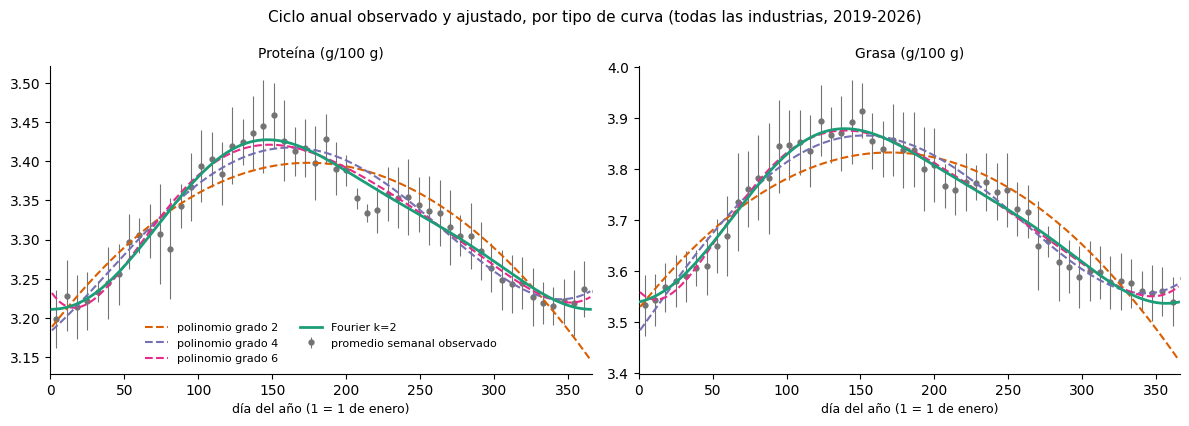

In [6]:
D["sem_anio"] = (D["doy"] - 1) // 7                 # semana del año 0..52
obs = {v: RL.se_por_bin(D[v].to_numpy(), D["sem_anio"].to_numpy(), D["bloque"].to_numpy()) for v in OBJ}
ajustes = {f"polinomio grado {g}": [("poly", g)] for g in range(1, 7)}
ajustes.update({f"Fourier k={k}": [("fourier", k)] for k in (1, 2, 3)})
curvas, saltos = {}, []
for nombre, comps in ajustes.items():
    m = RL.construir(comps).fit(D, Y)
    cu = RL.curva_anual(m, D)
    curvas[nombre] = cu
    saltos.append({"modelo": nombre, **{f"salto 31-dic → 1-ene, {v} (g/100 g)": cu[0, j] - cu[-1, j] for j, v in enumerate(OBJ)},
                   **{f"rango anual, {v}": np.ptp(cu[:, j]) for j, v in enumerate(OBJ)}})
saltos = pd.DataFrame(saltos)
print("Salto entre el 31-dic y el 1-ene de cada curva (y rango de la curva en el año):")
print(saltos.round(4).to_string(index=False))
saltos.to_csv(SALIDA / "saltos_diciembre_enero.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
estilos = {"polinomio grado 2": ("#d95f02", "--"), "polinomio grado 4": ("#7570b3", "--"), "polinomio grado 6": ("#e7298a", "--"), "Fourier k=2": ("#1b9e77", "-")}
dias = np.arange(1, 366)
for j, v in enumerate(OBJ):
    a = ax[j]
    o = obs[v]
    a.errorbar(o["bin"] * 7 + 4, o["media"], yerr=1.96 * o["se"], fmt="o", color="0.45", ms=3.5, lw=0.8, label="promedio semanal observado", zorder=1)
    for nombre, (col, ls) in estilos.items():
        a.plot(dias, curvas[nombre][:, j], color=col, ls=ls, lw=2 if "Fourier" in nombre else 1.5, label=nombre, zorder=3)
    a.set_title(("Proteína" if v == "proteina" else "Grasa") + " (g/100 g)"); a.set_xlabel("día del año (1 = 1 de enero)")
    a.set_xlim(0, 366)
    if j == 0: a.legend(loc="lower center", ncol=2)
fig.suptitle("Ciclo anual observado y ajustado, por tipo de curva (todas las industrias, 2019-2026)", fontsize=11)
fig.tight_layout(); fig.savefig(SALIDA / "fig1_ciclo_observado_vs_ajustado.png", dpi=DPI); plt.show()

**En simple:** los puntos grises son lo que se midió en promedio cada semana del año; las líneas son lo que cada modelo dice que es «lo normal» para esa fecha.
Si una línea sigue a los puntos, capta el ciclo; si en los bordes (principio y fin del año) se va para otro lado o no coincide entre el 31 de diciembre y el 1.º
de enero, es el defecto del polinomio, que no sabe que el año es un círculo. La tabla de arriba pone en números ese salto.

## 4 · Temperatura, estación y anomalía
La temperatura sube y baja con las estaciones, igual que la composición de la leche. Si se la usa sola, lleva el efecto de la estación. Para separarlos
se calcula, para cada día, la **anomalía** = temperatura media de los últimos N días menos su **climatología** (el ciclo medio de la temperatura, ajustado con
3 armónicos usando solo los años 2015–2023 y sin mirar la leche). La anomalía es cuánto más caluroso o más frío estuvo respecto de lo normal para esa fecha.

In [7]:
filas = []
for n in RL.VENTANAS_T:
    t, an = D[f"t{n}"], D[f"an{n}"]
    f = {"ventana (días)": n, "sd temperatura (°C)": t.std(), "sd anomalía (°C)": an.std(),
         "% de la varianza de la temperatura que es estación": 100 * (1 - an.var() / t.var())}
    for v in OBJ:
        f[f"corr {v} con temperatura"] = np.corrcoef(D[v], t)[0, 1]
        f[f"corr {v} con anomalía"] = np.corrcoef(D[v], an)[0, 1]
    filas.append(f)
print(pd.DataFrame(filas).round(3).to_string(index=False))

 ventana (días)  sd temperatura (°C)  sd anomalía (°C)  % de la varianza de la temperatura que es estación  corr proteina con temperatura  corr proteina con anomalía  corr grasa con temperatura  corr grasa con anomalía
              7                6.167             2.567                                              82.672                         -0.396                      -0.200                      -0.278                   -0.109
             14                6.005             2.061                                              88.217                         -0.381                      -0.210                      -0.265                   -0.111
             30                5.802             1.526                                              93.081                         -0.330                      -0.176                      -0.228                   -0.096


## 5 · Todos los modelos, con validación temporal
Se arma una grilla de modelos de menor a mayor complejidad (para cada objetivo, proteína y grasa, que se ajustan juntos con `LinearRegression`).
Primero los de **forma del ciclo**: las referencias (media global, media por industria), el mes como one-hot, polinomios de grado 1 a 6 y Fourier de k = 1 a 3.
Para cada uno: error **de entrenamiento** (ajustado hasta 2023), de **validación** (ventana que crece por año, 2021–2023) y de **prueba** (ajustado hasta 2023, probado 2024–2026).

In [8]:
MA = {"media global": [], "media por industria": [("industria",)], "mes (one-hot)": [("mes",)]}
for g in range(1, 7): MA[f"polinomio grado {g}"] = [("poly", g)]
for k in (1, 2, 3): MA[f"Fourier k={k}"] = [("fourier", k)]
tmA, rodA = RL.tabla_modelos(D, MA)

def ancho(tm, nombres, etapa, metricas=("mae", "rmse", "r2", "rmse_sem")):
    t = tm[(tm["etapa"] == etapa) & tm["modelo"].isin(nombres)].pivot(index="modelo", columns="objetivo", values=list(metricas))
    t = t.loc[list(nombres)]
    t = t.reorder_levels([1, 0], axis=1).sort_index(axis=1, level=0, sort_remaining=False)
    return t[[(o, m) for o in OBJ for m in metricas]]

for etapa in ("entrenamiento", "validación 2021-23", "prueba 2024-26"):
    print(f"\n=== {etapa} (MAE, RMSE y R² por muestra; rmse_sem = RMSE de los promedios semanales por industria; g/100 g) ===")
    print(ancho(tmA, MA, etapa).round(4).to_string())
tmA.to_csv(SALIDA / "metricas_ciclo.csv", index=False)


=== entrenamiento (MAE, RMSE y R² por muestra; rmse_sem = RMSE de los promedios semanales por industria; g/100 g) ===
objetivo            proteina                            grasa                         
                         mae    rmse      r2 rmse_sem     mae    rmse      r2 rmse_sem
modelo                                                                                
media global          0.1262  0.1617  0.0000   0.0908  0.2380  0.3257  0.0000   0.1491
media por industria   0.1257  0.1609  0.0098   0.0898  0.2366  0.3240  0.0102   0.1436
mes (one-hot)         0.1128  0.1465  0.1790   0.0572  0.2186  0.3068  0.1130   0.1032
polinomio grado 1     0.1258  0.1611  0.0073   0.0892  0.2368  0.3246  0.0066   0.1461
polinomio grado 2     0.1140  0.1481  0.1609   0.0610  0.2203  0.3084  0.1033   0.1081
polinomio grado 3     0.1137  0.1476  0.1667   0.0594  0.2189  0.3070  0.1113   0.1037
polinomio grado 4     0.1134  0.1472  0.1714   0.0585  0.2185  0.3067  0.1133   0.1031
polinomio g

## 6 · Elegir el grado por validación (sobreajuste)
**Regla.** De los modelos de forma del ciclo (mes, polinomios, Fourier) se mira el error de **validación** (solo 2021–2023, nunca la prueba). Se calcula un
puntaje: el RMSE semanal de cada modelo dividido por el mejor, promediado entre proteína y grasa. Se elige el modelo **más simple (menos parámetros) que quede
a menos del 0,5 % del mejor**; si hay empate en parámetros, gana el cíclico (Fourier). Abajo se ve qué pasaría con otras tolerancias,
y por qué importa: un ciclo de un solo armónico es una onda simétrica (el pico cae justo medio año después del mínimo), y el segundo armónico le permite subir más rápido de lo que baja.

In [9]:
cand = ["media por industria", "mes (one-hot)"] + [f"Fourier k={k}" for k in (1, 2, 3)] + [f"polinomio grado {g}" for g in range(1, 7)]
n_par = {n: RL.n_parametros(MA[n], D) for n in cand}
ciclo_nombre, sel = RL.elegir(tmA, cand, n_par)
print(sel.round(4).to_string())
print("\nelegido:", ciclo_nombre, "·", n_par[ciclo_nombre], "parámetros del ciclo")
print("sensibilidad a la tolerancia:", {f"{100 * t:.1f} %": RL.elegir(tmA, cand, n_par, t)[0] for t in (0, 0.005, 0.01)})
CICLO = MA[ciclo_nombre]
print("\nPico y mínimo de la curva según el número de armónicos (ajuste con todos los datos):")
pm = []
for k in (1, 2, 3):
    amp, pk, mn = RL.ciclo_simple(D, D, [("fourier", k)])
    for j, v in enumerate(OBJ):
        pm.append({"armónicos": k, "objetivo": v, "amplitud (g/100 g)": amp[j], "pico": RL.dia_del_anio(pk[j]), "mínimo": RL.dia_del_anio(mn[j]), "días del mínimo al pico": (pk[j] - mn[j]) % 365})
print(pd.DataFrame(pm).round(3).to_string(index=False))

                     parámetros  puntaje  dentro de la tolerancia
media por industria           8   1.5333                    False
mes (one-hot)                12   1.0576                    False
Fourier k=1                   2   1.0117                    False
Fourier k=2                   4   1.0027                     True
Fourier k=3                   6   1.0189                    False
polinomio grado 1             1   1.5108                    False
polinomio grado 2             2   1.0400                    False
polinomio grado 3             3   1.0156                    False
polinomio grado 4             4   1.0143                    False
polinomio grado 5             5   1.0108                    False
polinomio grado 6             6   1.0184                    False

elegido: Fourier k=2 · 4 parámetros del ciclo
sensibilidad a la tolerancia: {'0.0 %': 'Fourier k=2', '0.5 %': 'Fourier k=2', '1.0 %': 'Fourier k=1'}

Pico y mínimo de la curva según el número de armónicos (a

 armónicos objetivo  amplitud (g/100 g)   pico mínimo  días del mínimo al pico
         1 proteina               0.204 15 jun 15 dic                      182
         1    grasa               0.325  8 jun  7 dic                      183
         2 proteina               0.216 27 may 31 dic                      147
         2    grasa               0.343 19 may 23 dic                      147
         3 proteina               0.226 26 may 19 dic                      158
         3    grasa               0.333  9 may 28 dic                      132


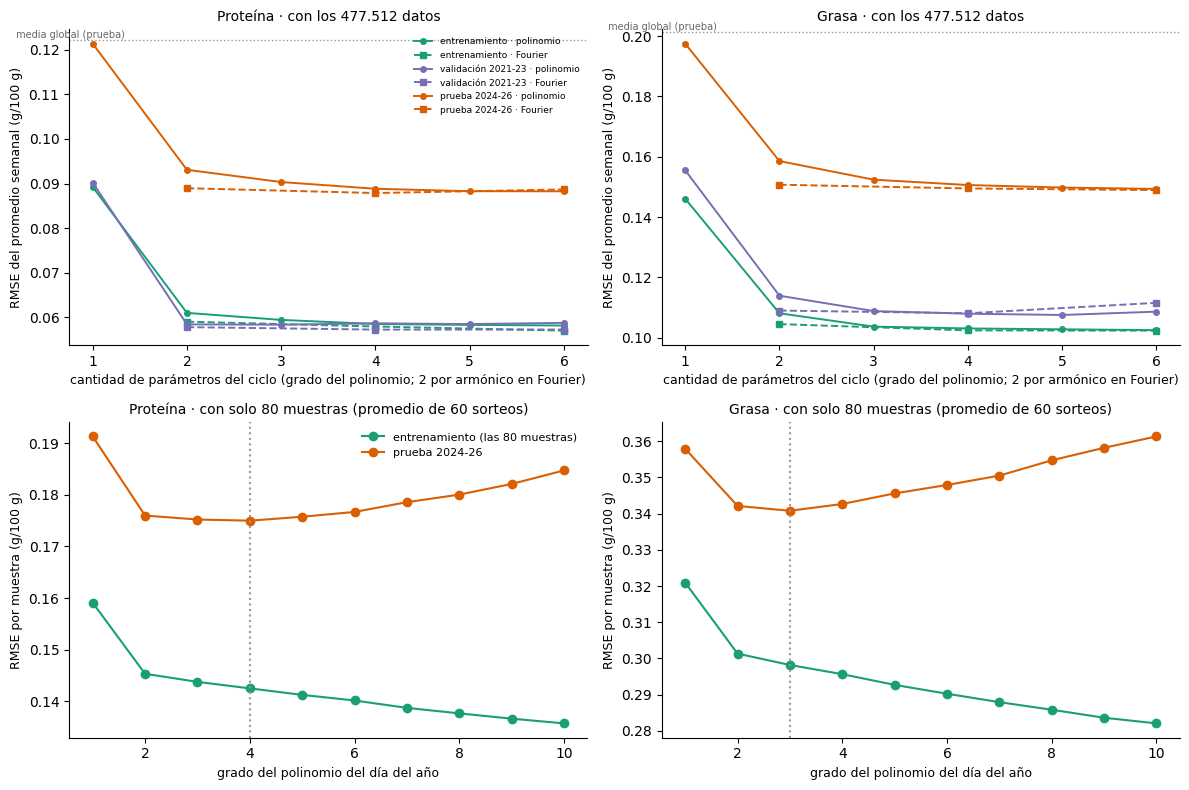

grado con menor error de prueba usando 80 muestras: objetivo  grado  rmse_entrenamiento  rmse_prueba
   grasa      3              0.2982       0.3408
proteina      4              0.1425       0.1750
proteina: con 80 muestras el error de prueba es mínimo en el grado 4 (0.1750); con grado 1 es 0.1913 y con grado 10 es 0.1847 (5.6 % más que en el mínimo); grado 10 queda mejor que el grado 1, pero peor que el mínimo.
grasa: con 80 muestras el error de prueba es mínimo en el grado 3 (0.3408); con grado 1 es 0.3579 y con grado 10 es 0.3613 (6.0 % más que en el mínimo); grado 10 queda peor que el grado 1.


In [10]:
# Curva de error según la complejidad: entrenamiento, validación y prueba (arriba, con todos los datos) y el mismo experimento con pocas muestras (abajo)
N_POCAS, SORTEOS = 80, 60
pocas = RL.curva_pocas_muestras(D, grados=range(1, 11), n=N_POCAS, sorteos=SORTEOS)
col = {"entrenamiento": "#1b9e77", "validación 2021-23": "#7570b3", "prueba 2024-26": "#d95f02"}
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for j, v in enumerate(OBJ):
    a = ax[0, j]
    for etapa, cc in col.items():
        for fam, pref, ls, mk in (("polinomio", "polinomio grado ", "-", "o"), ("Fourier", "Fourier k=", "--", "s")):
            ns = [n for n in MA if n.startswith(pref)]
            x = [n_par[n] if n in n_par else RL.n_parametros(MA[n], D) for n in ns]
            y = [tmA[(tmA["modelo"] == n) & (tmA["etapa"] == etapa) & (tmA["objetivo"] == v)]["rmse_sem"].iloc[0] for n in ns]
            a.plot(x, y, ls=ls, marker=mk, color=cc, ms=4, lw=1.4, label=f"{etapa} · {fam}")
    ref = tmA[(tmA["modelo"] == "media global") & (tmA["etapa"] == "prueba 2024-26") & (tmA["objetivo"] == v)]["rmse_sem"].iloc[0]
    a.axhline(ref, color="0.6", ls=":", lw=1); a.text(0.15, ref, " media global (prueba)", va="bottom", fontsize=7, color="0.4")
    a.set_title(f"{'Proteína' if v == 'proteina' else 'Grasa'} · con los {miles(len(D))} datos")
    a.set_xlabel("cantidad de parámetros del ciclo (grado del polinomio; 2 por armónico en Fourier)"); a.set_ylabel("RMSE del promedio semanal (g/100 g)")
    if j == 0: a.legend(fontsize=6.5, ncol=1, loc="upper right")
    b = ax[1, j]
    p = pocas[pocas["objetivo"] == v]
    b.plot(p["grado"], p["rmse_entrenamiento"], "o-", color=col["entrenamiento"], label="entrenamiento (las %d muestras)" % N_POCAS)
    b.plot(p["grado"], p["rmse_prueba"], "o-", color=col["prueba 2024-26"], label="prueba 2024-26")
    gmin = int(p.loc[p["rmse_prueba"].idxmin(), "grado"]); b.axvline(gmin, color="0.6", ls=":")
    b.set_title(f"{'Proteína' if v == 'proteina' else 'Grasa'} · con solo {N_POCAS} muestras (promedio de {SORTEOS} sorteos)")
    b.set_xlabel("grado del polinomio del día del año"); b.set_ylabel("RMSE por muestra (g/100 g)")
    if j == 0: b.legend()
fig.tight_layout(); fig.savefig(SALIDA / "fig2_error_vs_grado.png", dpi=DPI); plt.show()
print("grado con menor error de prueba usando %d muestras:" % N_POCAS, pocas.loc[pocas.groupby("objetivo")["rmse_prueba"].idxmin(), ["objetivo", "grado", "rmse_entrenamiento", "rmse_prueba"]].round(4).to_string(index=False))
pocas.to_csv(SALIDA / "sobreajuste_pocas_muestras.csv", index=False)
for v in OBJ:
    q = pocas[pocas["objetivo"] == v].set_index("grado")["rmse_prueba"]
    gm = int(q.idxmin())
    print(f"{v}: con {N_POCAS} muestras el error de prueba es mínimo en el grado {gm} ({q[gm]:.4f}); con grado 1 es {q[1]:.4f} y con grado 10 es {q[10]:.4f} ({100 * (q[10] / q[gm] - 1):.1f} % más que en el mínimo)"
          + ("; grado 10 queda peor que el grado 1." if q[10] > q[1] else "; grado 10 queda mejor que el grado 1, pero peor que el mínimo."))

**En simple:** de izquierda a derecha el modelo se hace más flexible. Arriba, con casi 480 mil datos: pasar de 1 a 2 parámetros baja mucho el error (es la diferencia entre
una recta y una curva que sube y baja), pero de ahí en adelante el de entrenamiento casi no cambia y el de validación y el de prueba dejan de mejorar (con tres armónicos en la
grasa, incluso empeora un poco la validación). Con datos de sobra, más curvas ni ayudan ni hacen mucho daño. Abajo está la lección clásica: con solo 80 muestras, a medida que se
le agregan curvas al polinomio **el error con los datos que ya vio baja siempre, pero el de los datos nuevos tiene un mínimo en un grado bajo y sube después** (la línea de abajo de la figura dice cuál es el
grado del mínimo y cuánto más error hay con grado 10): se está aprendiendo el ruido, no el ciclo.

## 7 · ¿Qué agrega la temperatura sobre la estación?
Sobre el ciclo elegido se suman, de a uno, la **industria**, la **temperatura** y la **anomalía** (ventanas de 7, 14 y 30 días; lineal y con término cuadrático para el estrés por calor).
Dos modelos extra sirven para el diagnóstico: la **temperatura sola** (sin ciclo; lleva la confusión estación–temperatura) y la **temperatura absoluta junto con el ciclo**
(debería ser lo mismo que la anomalía: controlar por la estación es lo mismo que restarle la climatología). Y una **tendencia lineal** (años), como modelo aparte, para el
corrimiento que no es estacional visto en la sección 2.

In [11]:
MB = {"ciclo": CICLO, "ciclo + industria": CICLO + [("industria",)], "ciclo + tendencia": CICLO + [("tendencia",)],
      "ciclo + industria + tendencia": CICLO + [("industria",), ("tendencia",)]}
for n in RL.VENTANAS_T:
    MB[f"temperatura sola {n} d"] = [("temp", n, 1)]
    MB[f"ciclo + temperatura absoluta {n} d"] = CICLO + [("temp", n, 1)]
    MB[f"ciclo + anomalía {n} d"] = CICLO + [("anom", n, 1)]
    MB[f"ciclo + anomalía {n} d (grado 2)"] = CICLO + [("anom", n, 2)]
    MB[f"ciclo + industria + anomalía {n} d"] = CICLO + [("industria",), ("anom", n, 1)]
    MB[f"ciclo + industria + anomalía {n} d (grado 2)"] = CICLO + [("industria",), ("anom", n, 2)]
    MB[f"ciclo + anomalía {n} d + tendencia"] = CICLO + [("anom", n, 1), ("tendencia",)]
MB["temperatura sola 7 d (grado 2)"] = [("temp", 7, 2)]
tmB, rodB = RL.tabla_modelos(D, MB)
tm = pd.concat([tmA[~tmA["modelo"].isin(MB)], tmB], ignore_index=True)
rod = {**rodA, **rodB}
tm.to_csv(SALIDA / "metricas_todas.csv", index=False)

principales = ["ciclo", "ciclo + industria"] + [f"ciclo + anomalía {n} d" for n in RL.VENTANAS_T] + \
              [f"ciclo + anomalía {n} d (grado 2)" for n in RL.VENTANAS_T] + [f"ciclo + industria + anomalía {n} d" for n in RL.VENTANAS_T]
for etapa in ("validación 2021-23", "prueba 2024-26"):
    print(f"\n=== {etapa} ===")
    print(ancho(tm, ["media global"] + principales, etapa).round(4).to_string())


=== validación 2021-23 ===
objetivo                          proteina                            grasa                         
                                       mae    rmse      r2 rmse_sem     mae    rmse      r2 rmse_sem
modelo                                                                                              
media global                        0.1256  0.1608 -0.0189   0.0904  0.2422  0.3323 -0.0483   0.1587
ciclo                               0.1127  0.1461  0.1594   0.0572  0.2217  0.3113  0.0797   0.1081
ciclo + industria                   0.1125  0.1457  0.1637   0.0585  0.2217  0.3111  0.0811   0.1094
ciclo + anomalía 7 d                0.1112  0.1444  0.1782   0.0528  0.2210  0.3107  0.0836   0.1064
ciclo + anomalía 14 d               0.1114  0.1447  0.1750   0.0541  0.2214  0.3110  0.0814   0.1074
ciclo + anomalía 30 d               0.1128  0.1463  0.1570   0.0581  0.2218  0.3114  0.0793   0.1083
ciclo + anomalía 7 d (grado 2)      0.1113  0.1445  0.1773   0.

In [12]:
# Elección de la ventana y de los términos con la validación (2021-23) solo. Se compara ciclo / + industria / + anomalía (lineal y grado 2), con y sin industria.
cand_T = ["ciclo", "ciclo + industria"] + [f"ciclo + anomalía {n} d" for n in RL.VENTANAS_T] + [f"ciclo + anomalía {n} d (grado 2)" for n in RL.VENTANAS_T] \
         + [f"ciclo + industria + anomalía {n} d" for n in RL.VENTANAS_T] + [f"ciclo + industria + anomalía {n} d (grado 2)" for n in RL.VENTANAS_T]
n_par_T = {n: RL.n_parametros(MB[n], D) for n in cand_T}
elegido_nombre, selT = RL.elegir(tm, cand_T, n_par_T)
print(selT.round(4).to_string())
print("\nmodelo elegido:", elegido_nombre, "·", n_par_T[elegido_nombre], "parámetros ·", MB[elegido_nombre])
# ventana de temperatura con mejor validación entre los modelos "ciclo + anomalía N d"
pv = RL.puntaje_validacion(tm, [f"ciclo + anomalía {n} d" for n in RL.VENTANAS_T])
NSTAR = RL.VENTANAS_T[int(np.argmin(pv.to_numpy()))]
print("ventana con mejor validación (ciclo + anomalía N d):", NSTAR, "días")
ELEGIDO = MB[elegido_nombre]

                                             parámetros  puntaje  dentro de la tolerancia
ciclo                                                 4   1.0498                    False
ciclo + industria                                    12   1.0680                    False
ciclo + anomalía 7 d                                  5   1.0000                     True
ciclo + anomalía 14 d                                 5   1.0161                    False
ciclo + anomalía 30 d                                 5   1.0586                    False
ciclo + anomalía 7 d (grado 2)                        6   1.0035                     True
ciclo + anomalía 14 d (grado 2)                       6   1.0188                    False
ciclo + anomalía 30 d (grado 2)                       6   1.0515                    False
ciclo + industria + anomalía 7 d                     13   1.0229                    False
ciclo + industria + anomalía 14 d                    13   1.0393                    False
ciclo + in

In [13]:
# Cuánto agrega la temperatura sobre la estación: ciclo vs ciclo + anomalía (ventana elegida), en cada etapa
base, con_t, cuad = "ciclo", f"ciclo + anomalía {NSTAR} d", f"ciclo + anomalía {NSTAR} d (grado 2)"
filas = []
for etapa in ("validación 2021-23", "prueba 2024-26"):
    for v in OBJ:
        g = lambda n, m: tm[(tm["modelo"] == n) & (tm["etapa"] == etapa) & (tm["objetivo"] == v)][m].iloc[0]
        for m in ("rmse", "rmse_sem", "mae", "r2"):
            filas.append({"etapa": etapa, "objetivo": v, "métrica": m, "media global": g("media global", m), "ciclo": g(base, m),
                          "ciclo + anomalía": g(con_t, m), "ciclo + anomalía grado 2": g(cuad, m)})
aporte = pd.DataFrame(filas)
aporte["mejora de la anomalía sobre el ciclo (%)"] = np.where(aporte["métrica"] == "r2", np.nan, 100 * (1 - aporte["ciclo + anomalía"] / aporte["ciclo"]))
aporte["mejora del grado 2 sobre el lineal (%)"] = np.where(aporte["métrica"] == "r2", np.nan, 100 * (1 - aporte["ciclo + anomalía grado 2"] / aporte["ciclo + anomalía"]))
print(f"Ventana elegida: {NSTAR} días. Mejora = reducción del error (positivo = mejor).")
print(aporte.round(4).to_string(index=False))
aporte.to_csv(SALIDA / "aporte_temperatura.csv", index=False)

print("\nDiagnóstico de la confusión (prueba 2024-26, RMSE semanal): la temperatura sola vs el ciclo, y la absoluta con ciclo vs la anomalía con ciclo")
dg = ancho(tm, ["media global", base, f"temperatura sola {NSTAR} d", f"ciclo + temperatura absoluta {NSTAR} d", con_t], "prueba 2024-26", ("rmse", "rmse_sem", "r2"))
print(dg.round(4).to_string())

Ventana elegida: 7 días. Mejora = reducción del error (positivo = mejor).
             etapa objetivo  métrica  media global  ciclo  ciclo + anomalía  ciclo + anomalía grado 2  mejora de la anomalía sobre el ciclo (%)  mejora del grado 2 sobre el lineal (%)
validación 2021-23 proteina     rmse        0.1608 0.1461            0.1444                    0.1445                                    1.1268                                 -0.0582
validación 2021-23 proteina rmse_sem        0.0904 0.0572            0.0528                    0.0531                                    7.7080                                 -0.4615
validación 2021-23 proteina      mae        0.1256 0.1127            0.1112                    0.1113                                    1.3343                                 -0.0879
validación 2021-23 proteina       r2       -0.0189 0.1594            0.1782                    0.1773                                       NaN                                     NaN
valida

## 8 · Año por año (ventana que crece) y el corrimiento de nivel
Para ver si lo anterior se sostiene, la ventana que crece por año da el error de cada año (se entrena con todo lo anterior a ese año). Se incluye la
**tendencia lineal**, que no es estacional: ¿ayuda a predecir el nivel de los años siguientes?

In [14]:
noms = ["media global", "ciclo", "ciclo + industria", f"ciclo + anomalía {NSTAR} d", elegido_nombre, "ciclo + tendencia", f"ciclo + anomalía {NSTAR} d + tendencia"]
noms = list(dict.fromkeys(noms))
py = RL.por_anio(D, {n: rod[n] for n in noms})
for m in ("rmse", "rmse_sem"):
    print(f"\n{m} por año de la ventana que crece (g/100 g):")
    print(py.pivot_table(index=["objetivo", "modelo"], columns="anio", values=m, sort=False).reindex([(o, n) for o in OBJ for n in noms]).round(4).to_string())
mej = py.pivot_table(index=["objetivo", "anio"], columns="modelo", values="rmse_sem")
for v in OBJ:
    mv = mej.loc[v]
    print(f"\n{v}: años (de {len(mv)}) en que 'ciclo + anomalía {NSTAR} d' tiene menor RMSE semanal que 'ciclo':", int((mv[f'ciclo + anomalía {NSTAR} d'] < mv['ciclo']).sum()),
          "· años en que 'ciclo + tendencia' lo tiene menor que 'ciclo':", int((mv['ciclo + tendencia'] < mv['ciclo']).sum()))
py.to_csv(SALIDA / "metricas_por_anio.csv", index=False)


rmse por año de la ventana que crece (g/100 g):
anio                                         2021    2022    2023    2024    2025    2026
objetivo modelo                                                                          
proteina media global                      0.1617  0.1649  0.1558  0.1808  0.1832  0.2086
         ciclo                             0.1467  0.1470  0.1446  0.1657  0.1697  0.1793
         ciclo + industria                 0.1468  0.1463  0.1441  0.1648  0.1675  0.1781
         ciclo + anomalía 7 d              0.1458  0.1442  0.1435  0.1617  0.1686  0.1736
         ciclo + tendencia                 0.1672  0.1547  0.1509  0.1662  0.1690  0.1685
         ciclo + anomalía 7 d + tendencia  0.1644  0.1505  0.1470  0.1633  0.1655  0.1620
grasa    media global                      0.3252  0.3490  0.3207  0.3309  0.3476  0.3917
         ciclo                             0.3044  0.3236  0.3044  0.3120  0.3307  0.3537
         ciclo + industria                 0.3016  

**Lectura.** Sumar la anomalía de temperatura mejora el error semanal en casi todos los años (en cuántos, arriba). La tendencia lineal, en cambio, no es confiable: cuando se la estima con pocos años
(2019–2020 para predecir 2021) empeora mucho la proteína, y recién ayuda en 2026; en la grasa ayuda en la mayoría de los años pero no en todos. El nivel de la composición se corrió, pero no a un ritmo
constante que se pueda extrapolar con seguridad.

## 9 · Residuos en el tiempo
Residuo = valor medido − lo que predice el **modelo elegido** (ajustado hasta 2023). Se promedia por mes; las líneas finas son cada industria (con 60 o más
meses de datos) y la gruesa, el promedio de todas.

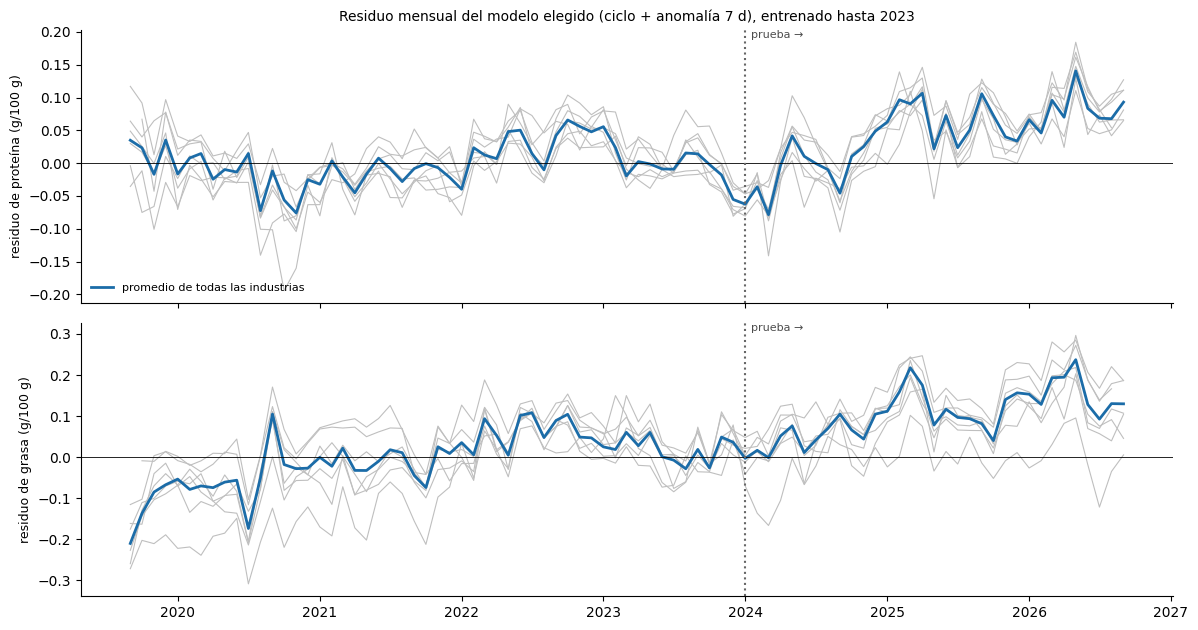

proteina: residuo medio mensual en el entrenamiento -0.001 · en la prueba (2024-26) +0.043 g/100 g
grasa: residuo medio mensual en el entrenamiento -0.004 · en la prueba (2024-26) +0.104 g/100 g


In [15]:
ent = (D["fecha"] <= RL.FIN_ENTRENAMIENTO).to_numpy()
m_el = RL.construir(ELEGIDO).fit(D[ent], Y[ent])
res_t = Y - m_el.predict(D)
D["mes_f"] = D["fecha"].dt.to_period("M").dt.to_timestamp()
fig, ax = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True)
resumen_res = []
for j, v in enumerate(OBJ):
    t = pd.DataFrame({"cliente": D["cliente"], "mes": D["mes_f"], "r": res_t[:, j]})
    pm = t.pivot_table(index="mes", columns="cliente", values="r", aggfunc="mean")
    cnt = t.pivot_table(index="mes", columns="cliente", values="r", aggfunc="size")
    pm = pm.where(cnt >= 30)
    todas = t.groupby("mes")["r"].agg(["mean", "size"]); todas = todas[todas["size"] >= 100]["mean"]
    a = ax[j]
    for cli in pm.columns:
        if pm[cli].notna().sum() >= 60: a.plot(pm.index, pm[cli], color="0.75", lw=0.8)
    a.plot(todas.index, todas, color="#1b6ca8", lw=2, label="promedio de todas las industrias")
    a.axhline(0, color="k", lw=0.6); a.axvline(pd.Timestamp("2024-01-01"), color="0.4", ls=":")
    a.text(pd.Timestamp("2024-01-15"), a.get_ylim()[1], "prueba →", va="top", fontsize=8, color="0.3")
    a.set_ylabel(f"residuo de {'proteína' if v == 'proteina' else 'grasa'} (g/100 g)")
    resumen_res.append((v, todas[todas.index <= "2023-12-01"].mean(), todas[todas.index > "2023-12-01"].mean()))
ax[0].legend(loc="lower left"); ax[0].set_title(f"Residuo mensual del modelo elegido ({elegido_nombre}), entrenado hasta 2023")
fig.tight_layout(); fig.savefig(SALIDA / "fig3_residuos_en_el_tiempo.png", dpi=DPI); plt.show()
for v, a_, b_ in resumen_res:
    print(f"{v}: residuo medio mensual en el entrenamiento {a_:+.3f} · en la prueba (2024-26) {b_:+.3f} g/100 g")

**En simple:** cada punto es cuánto se equivocó el modelo en promedio ese mes (sobre cero: la leche tuvo más de lo que el modelo esperaba; bajo cero: menos). Si el modelo
captara todo lo que es regular, los residuos oscilarían al azar alrededor de cero. Las curvas grises de las industrias suben y bajan casi juntas, y en la zona de prueba
el promedio se corre del cero: queda un movimiento común, de varios meses, que no es estacional y que este modelo no explica.

## 10 · Industria dejada afuera
¿El ciclo estimado con unas industrias sirve para otra? Con `GroupKFold` por industria, cada industria se deja afuera, el modelo se ajusta con las demás y se prueba en ella (se compara con
la media global de las demás). No pueden llevar el término de industria: una industria nueva no tiene efecto propio. Se hace de dos formas: (a) con todos los años (¿se generaliza **entre industrias**?) y
(b) ajustando hasta 2023 y probando 2024–2026 en la industria que quedó afuera (industria **nueva y período futuro** a la vez).

In [16]:
MC = {"media global": [], "ciclo": CICLO, f"ciclo + anomalía {NSTAR} d": CICLO + [("anom", NSTAR, 1)]}
lo_a = RL.industria_afuera(D, MC, solo_pasado=False)
lo_b = RL.industria_afuera(D, MC, solo_pasado=True)
lo_a.insert(0, "esquema", "(a) todos los años"); lo_b.insert(0, "esquema", "(b) hasta 2023 → 2024-26")
lo = pd.concat([lo_a, lo_b], ignore_index=True)
lo.to_csv(SALIDA / "industria_afuera.csv", index=False)
for esq, g in lo.groupby("esquema", sort=False):
    print(f"\n=== {esq} ===")
    for m in ("rmse", "rmse_sem"):
        t = g.pivot_table(index=["objetivo", "industria"], columns="modelo", values=m, sort=False)[list(MC)]
        t["mejora del ciclo sobre la media (%)"] = 100 * (1 - t["ciclo"] / t["media global"])
        t["mejora de la anomalía sobre el ciclo (%)"] = 100 * (1 - t[f"ciclo + anomalía {NSTAR} d"] / t["ciclo"])
        print(f"\n{m}:"); print(t.round(4).to_string())
    n = g[g["modelo"] == "ciclo"].set_index(["objetivo", "industria"])["n"]
    for v in OBJ:
        t = g.pivot_table(index=["objetivo", "industria"], columns="modelo", values="rmse_sem", sort=False).loc[v]
        t2 = g.pivot_table(index=["objetivo", "industria"], columns="modelo", values="rmse", sort=False).loc[v]
        print(f"-> {v}: el ciclo baja el RMSE por muestra en {int((t2['ciclo'] < t2['media global']).sum())} de {len(t2)} industrias y el RMSE semanal en {int((t['ciclo'] < t['media global']).sum())} de {len(t)}")


=== (a) todos los años ===

rmse:
modelo              media global   ciclo  ciclo + anomalía 7 d  mejora del ciclo sobre la media (%)  mejora de la anomalía sobre el ciclo (%)
objetivo industria                                                                                                                           
proteina IND-81           0.1754  0.1600                0.1575                               8.7715                                    1.5685
         IND-68           0.1748  0.1597                0.1582                               8.5994                                    0.9763
         IND-59           0.1573  0.1420                0.1389                               9.6973                                    2.2184
         IND-88           0.1825  0.1660                0.1639                               9.0881                                    1.2342
         IND-29           0.1631  0.1416                0.1397                              13.1764              

## 11 · Interpretación: amplitud, pico y efecto de 1 °C de anomalía
El modelo para interpretar es el ciclo elegido **más la industria como control** (para que el efecto de la temperatura sea dentro de cada industria) y la anomalía de la
ventana elegida; se ajusta con **todos los datos** (2019–2026) y los intervalos de 95 % salen de **1000 remuestreos de bloques de 28 días** (y, para comparar, de semanas sueltas).
Las ecuaciones normales por bloque dan exactamente los mismos coeficientes que `LinearRegression` (el notebook lo verifica).

In [17]:
comps_int = CICLO + [("industria",), ("anom", NSTAR, 2)]
aj28 = RL.ajuste_bloques(comps_int, D, bloque="bloque", B=B)
ajsem = RL.ajuste_bloques(comps_int, D, bloque="sem_id", B=B)
print(f"modelo de interpretación: {comps_int}\nmuestras {miles(aj28['n'])} · bloques de 28 días: {aj28['n_bloques']} · semanas: {ajsem['n_bloques']}")
for nombre, aj in (("bloques de 28 días", aj28), ("semanas", ajsem)):
    print(f"\n--- Ciclo anual estimado (IC 95 % por bootstrap de {nombre}) ---")
    ap = RL.amplitud_pico(aj, D)
    print(ap.round(3).to_string(index=False))
    if nombre.startswith("bloques"): ap.to_csv(SALIDA / "amplitud_pico.csv", index=False)

modelo de interpretación: [('fourier', 2), ('industria',), ('anom', 7, 2)]
muestras 477.512 · bloques de 28 días: 93 · semanas: 366

--- Ciclo anual estimado (IC 95 % por bootstrap de bloques de 28 días) ---
objetivo  amplitud pico a pico (g/100 g)  ic95 inf  ic95 sup  % del promedio   pico      pico ic95 mínimo    mínimo ic95
proteina                           0.206     0.179     0.237           6.211 25 may 14 may a 9 jun 30 dic 19 dic a 9 ene
   grasa                           0.333     0.292     0.381           8.962 17 may  3 may a 5 jun 23 dic 10 dic a 2 ene

--- Ciclo anual estimado (IC 95 % por bootstrap de semanas) ---
objetivo  amplitud pico a pico (g/100 g)  ic95 inf  ic95 sup  % del promedio   pico      pico ic95 mínimo     mínimo ic95
proteina                           0.206     0.190     0.223           6.211 25 may 18 may a 3 jun 30 dic  23 dic a 5 ene
   grasa                           0.333     0.307     0.360           8.962 17 may 8 may a 27 may 23 dic 16 dic a 28 di

In [18]:
# ¿La fase y la amplitud se repiten año a año y entre industrias? (sin bootstrap: ciclo estimado por separado en cada año / industria)
amp_pico_simple = lambda dd, comps: RL.ciclo_simple(dd, D, comps)
anual = []
for a in range(2020, 2026):
    dd = D[D["anio"] == a]
    amp, pk, mn = amp_pico_simple(dd, CICLO + [("industria",)])
    for j, v in enumerate(OBJ):
        anual.append({"año": a, "objetivo": v, "muestras": len(dd), "amplitud (g/100 g)": amp[j], "pico": RL.dia_del_anio(pk[j]), "mínimo": RL.dia_del_anio(mn[j]), "pico (día)": pk[j]})
anual = pd.DataFrame(anual)
print("Ciclo estimado año por año (años completos, ciclo + industria):"); print(anual.drop(columns="pico (día)").round(3).to_string(index=False))
for v in OBJ:
    pk = anual[anual["objetivo"] == v]["pico (día)"]
    print(f"{v}: día del pico entre años: mínimo {pk.min()}, máximo {pk.max()} (rango {pk.max() - pk.min()} días)")
por_ind = []
for cli, dd in D.groupby("cliente"):
    if dd["anio"].nunique() < 5 or len(dd) < 5000: continue
    amp, pk, mn = amp_pico_simple(dd, CICLO)
    for j, v in enumerate(OBJ):
        por_ind.append({"industria": cli, "objetivo": v, "muestras": len(dd), "amplitud (g/100 g)": amp[j], "pico": RL.dia_del_anio(pk[j]), "mínimo": RL.dia_del_anio(mn[j])})
por_ind = pd.DataFrame(por_ind)
print("\nCiclo estimado por industria (industrias con 5 años o más y 5000 muestras o más):"); print(por_ind.round(3).to_string(index=False))
anual.to_csv(SALIDA / "ciclo_por_anio.csv", index=False); por_ind.to_csv(SALIDA / "ciclo_por_industria.csv", index=False)

Ciclo estimado año por año (años completos, ciclo + industria):
 año objetivo  muestras  amplitud (g/100 g)   pico mínimo
2020 proteina     71773               0.218  9 jun 30 nov
2020    grasa     71773               0.290 12 may  4 ene
2021 proteina     62865               0.199  4 jun 31 dic
2021    grasa     62865               0.316  8 jun 10 dic
2022 proteina     75276               0.260 15 may 13 ene
2022    grasa     75276               0.375 20 may 30 dic
2023 proteina     74880               0.174 13 jun 20 dic
2023    grasa     74880               0.317 15 may 31 dic
2024 proteina     68887               0.253  5 jun  1 feb
2024    grasa     68887               0.324 30 may  5 ene
2025 proteina     65790               0.222  1 may 25 dic
2025    grasa     65790               0.323 10 may 15 dic
proteina: día del pico entre años: mínimo 121, máximo 164 (rango 43 días)
grasa: día del pico entre años: mínimo 130, máximo 159 (rango 29 días)

Ciclo estimado por industria (indust

In [19]:
# Efecto de 1 °C de anomalía (g/100 g por °C): ajuste lineal y con término cuadrático, y robustez
n_lin, n_cuad = f"anom__an{NSTAR}", f"anom__an{NSTAR}^2"
aj_lin28 = RL.ajuste_bloques(CICLO + [("industria",), ("anom", NSTAR, 1)], D, bloque="bloque", B=B)
aj_linsem = RL.ajuste_bloques(CICLO + [("industria",), ("anom", NSTAR, 1)], D, bloque="sem_id", B=B)
aj_tend = RL.ajuste_bloques(CICLO + [("industria",), ("anom", NSTAR, 1), ("tendencia",)], D, bloque="bloque", B=B)
aj_exac = RL.ajuste_bloques(CICLO + [("industria",), ("anom", NSTAR, 1)], D, bloque="bloque", B=B, mascara=D["exacta"].to_numpy())
aj_sola = RL.ajuste_bloques([("temp", NSTAR, 1)], D, bloque="bloque", B=B)
filas = []
def agregar(desc, aj, nombre):
    for v in OBJ:
        e, lo_, hi_ = RL.coef(aj, nombre, v)
        filas.append({"estimación": desc, "objetivo": v, "g/100 g por °C": e, "ic95 inf": lo_, "ic95 sup": hi_, "el 0 está dentro": lo_ <= 0 <= hi_})
agregar(f"anomalía {NSTAR} d, lineal, bloques de 28 d (principal)", aj_lin28, n_lin)
agregar(f"anomalía {NSTAR} d, lineal, semanas", aj_linsem, n_lin)
agregar(f"anomalía {NSTAR} d, lineal, con tendencia lineal", aj_tend, n_lin)
agregar(f"anomalía {NSTAR} d, lineal, solo fechas escritas en el informe ({miles(D['exacta'].sum())} muestras)", aj_exac, n_lin)
agregar(f"anomalía {NSTAR} d, lineal, ajuste con término cuadrático (parte lineal)", aj28, n_lin)
agregar(f"temperatura {NSTAR} d SOLA, sin ciclo (mezcla estación y temperatura)", aj_sola, f"temp__t{NSTAR}")
efecto = pd.DataFrame(filas)
print(f"Efecto de +1 °C de la temperatura (media de {NSTAR} días) sobre la composición, IC 95 %:")
print(efecto.round(4).to_string(index=False))
efecto.to_csv(SALIDA / "efecto_anomalia.csv", index=False)
for v in OBJ:
    e, lo_, hi_ = RL.coef(aj_tend, "tendencia__anios", v)
    print(f"tendencia lineal ({v}, en el ajuste con todos los datos): {e:+.4f} g/100 g por año (IC 95 % {lo_:+.4f} a {hi_:+.4f})")
print(f"\nSD de la anomalía de {NSTAR} días: {D[f'an{NSTAR}'].std():.2f} °C · percentiles 1 y 99: {D[f'an{NSTAR}'].quantile(.01):.1f} y {D[f'an{NSTAR}'].quantile(.99):.1f} °C")
for v in OBJ:
    e, lo_, hi_ = RL.coef(aj_lin28, n_lin, v)
    s = D[f"an{NSTAR}"].std()
    print(f"{v}: una anomalía de +1 sd ({s:.1f} °C) mueve la composición {e * s:+.3f} g/100 g (IC {lo_ * s:+.3f} a {hi_ * s:+.3f}), frente a un ciclo de punta a punta de {RL.amplitud_pico(aj28, D).set_index('objetivo').loc[v, 'amplitud pico a pico (g/100 g)']:.3f}")

Efecto de +1 °C de la temperatura (media de 7 días) sobre la composición, IC 95 %:
                                                                 estimación objetivo  g/100 g por °C  ic95 inf  ic95 sup  el 0 está dentro
                          anomalía 7 d, lineal, bloques de 28 d (principal) proteina         -0.0105   -0.0125   -0.0084             False
                          anomalía 7 d, lineal, bloques de 28 d (principal)    grasa         -0.0099   -0.0132   -0.0063             False
                                              anomalía 7 d, lineal, semanas proteina         -0.0105   -0.0123   -0.0086             False
                                              anomalía 7 d, lineal, semanas    grasa         -0.0099   -0.0126   -0.0069             False
                                 anomalía 7 d, lineal, con tendencia lineal proteina         -0.0109   -0.0128   -0.0090             False
                                 anomalía 7 d, lineal, con tendencia lineal    gras

In [20]:
# ¿Aporta el término cuadrático (estrés por calor)?
filas = []
for v in OBJ:
    e, lo_, hi_ = RL.coef(aj28, n_cuad, v); e2, lo2, hi2 = RL.coef(ajsem, n_cuad, v)
    filas.append({"objetivo": v, "coef. de a² (g/100 g por °C²), bloques 28 d": e, "ic95 inf": lo_, "ic95 sup": hi_, "0 dentro (28 d)": lo_ <= 0 <= hi_,
                  "ic95 semanas inf": lo2, "ic95 semanas sup": hi2, "0 dentro (semanas)": lo2 <= 0 <= hi2})
cu = pd.DataFrame(filas)
print(cu.round(5).to_string(index=False))
print()
for v in OBJ:
    c0 = RL.efecto_anomalia(aj28, n_lin, n_cuad, v, [-5, -3, 3, 5])
    cl0 = RL.efecto_anomalia(aj_lin28, n_lin, None, v, [-5, -3, 3, 5])
    print(f"{v}: efecto (g/100 g) de una anomalía de -5, -3, +3, +5 °C · modelo cuadrático:", np.round(c0[0], 3), "· modelo lineal:", np.round(cl0[0], 3))
print("\nPredicción (RMSE semanal): lineal vs cuadrático, validación y prueba:")
print(aporte[(aporte['métrica'] == 'rmse_sem')][["etapa", "objetivo", "ciclo", "ciclo + anomalía", "ciclo + anomalía grado 2", "mejora del grado 2 sobre el lineal (%)"]].round(4).to_string(index=False))
cu.to_csv(SALIDA / "termino_cuadratico.csv", index=False)

objetivo  coef. de a² (g/100 g por °C²), bloques 28 d  ic95 inf  ic95 sup  0 dentro (28 d)  ic95 semanas inf  ic95 semanas sup  0 dentro (semanas)
proteina                                      0.00016  -0.00034   0.00062             True          -0.00030           0.00065                True
   grasa                                      0.00071  -0.00017   0.00162             True          -0.00007           0.00146                True

proteina: efecto (g/100 g) de una anomalía de -5, -3, +3, +5 °C · modelo cuadrático: [ 0.058  0.034 -0.031 -0.05 ] · modelo lineal: [ 0.053  0.032 -0.032 -0.053]
grasa: efecto (g/100 g) de una anomalía de -5, -3, +3, +5 °C · modelo cuadrático: [ 0.072  0.039 -0.026 -0.037] · modelo lineal: [ 0.049  0.03  -0.03  -0.049]

Predicción (RMSE semanal): lineal vs cuadrático, validación y prueba:
             etapa objetivo  ciclo  ciclo + anomalía  ciclo + anomalía grado 2  mejora del grado 2 sobre el lineal (%)
validación 2021-23 proteina 0.0572            0

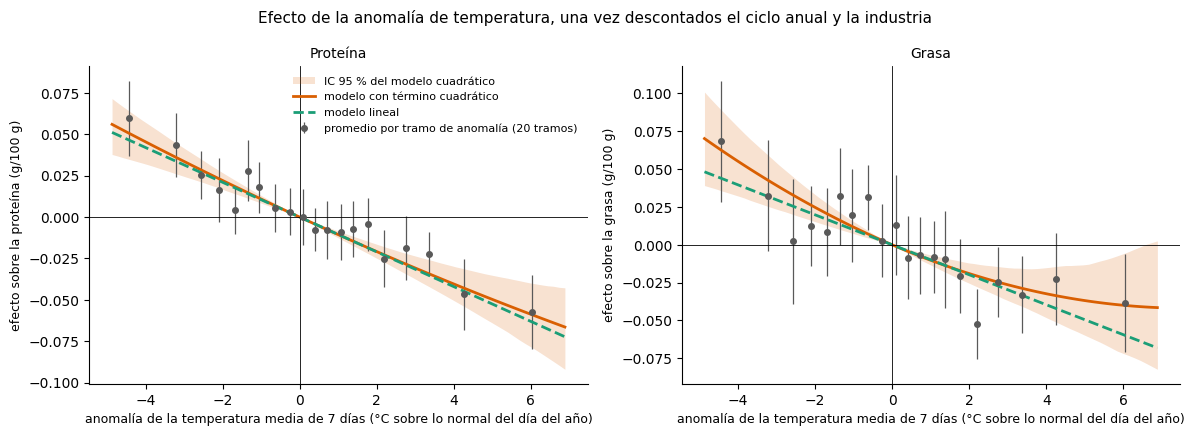

In [21]:
# Gráfico: efecto de la anomalía de temperatura sobre la composición (lo que queda después de sacar ciclo e industria)
m_ci = RL.construir(CICLO + [("industria",)]).fit(D, Y)
res_ci = Y - m_ci.predict(D)
an = D[f"an{NSTAR}"].to_numpy()
cortes = pd.qcut(an, 20, duplicates="drop")
grid = np.linspace(np.quantile(an, 0.01), np.quantile(an, 0.99), 80)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for j, v in enumerate(OBJ):
    s = RL.se_por_bin(res_ci[:, j], cortes, D["bloque"].to_numpy())
    xm = pd.Series(an).groupby(cortes, observed=True).mean().to_numpy()
    a = ax[j]
    a.errorbar(xm, s["media"], yerr=1.96 * s["se"], fmt="o", color="0.35", ms=4, lw=0.9, label="promedio por tramo de anomalía (20 tramos)", zorder=2)
    cen, lo_, hi_ = RL.efecto_anomalia(aj28, n_lin, n_cuad, v, grid)
    a.fill_between(grid, lo_, hi_, color="#d95f02", alpha=0.18, lw=0, label="IC 95 % del modelo cuadrático")
    a.plot(grid, cen, color="#d95f02", lw=2, label="modelo con término cuadrático")
    cl, ll, hl = RL.efecto_anomalia(aj_lin28, n_lin, None, v, grid)
    a.plot(grid, cl, color="#1b9e77", lw=2, ls="--", label="modelo lineal")
    a.axhline(0, color="k", lw=0.6); a.axvline(0, color="k", lw=0.6)
    a.set_xlabel(f"anomalía de la temperatura media de {NSTAR} días (°C sobre lo normal del día del año)")
    a.set_ylabel("efecto sobre " + ("la proteína" if v == "proteina" else "la grasa") + " (g/100 g)")
    a.set_title("Proteína" if v == "proteina" else "Grasa")
    if j == 0: a.legend(loc="upper right")
fig.suptitle("Efecto de la anomalía de temperatura, una vez descontados el ciclo anual y la industria", fontsize=11)
fig.tight_layout(); fig.savefig(SALIDA / "fig4_efecto_anomalia.png", dpi=DPI); plt.show()

**En simple:** cada punto agrupa los días en que hizo más o menos calor del normal para la época (a la derecha, más caluroso que lo habitual; a la izquierda, más frío) y muestra cuánto
quedó la composición por encima o por debajo de lo que explican la estación y la industria. Si los puntos bajan hacia la derecha, los períodos más cálidos que lo normal vienen con
menos proteína y grasa que lo esperable para esa época. La línea verde es el efecto «por grado» (recta) y la naranja deja que se curve; la banda es la incertidumbre.
Es una asociación: no prueba que el calor sea la causa.

## 12 · Conclusiones

In [22]:
def g(n, etapa, v, m):
    return tm[(tm["modelo"] == n) & (tm["etapa"] == etapa) & (tm["objetivo"] == v)][m].iloc[0]
ap = RL.amplitud_pico(aj28, D).set_index("objetivo")
print(f"Datos: {miles(len(D))} muestras de {D['cliente'].nunique()} industrias, {D['fecha'].min().date()} a {D['fecha'].max().date()}.")
print(f"Ciclo elegido por validación: {ciclo_nombre} ({n_par[ciclo_nombre]} parámetros). Modelo elegido con temperatura: {elegido_nombre}. Ventana de temperatura: {NSTAR} días.\n")
for v in OBJ:
    et = "prueba 2024-26"
    print(f"== {v} ==")
    print(f"  Ciclo: amplitud de punta a punta {ap.loc[v, 'amplitud pico a pico (g/100 g)']:.3f} g/100 g (IC {ap.loc[v, 'ic95 inf']:.3f}-{ap.loc[v, 'ic95 sup']:.3f}), "
          f"{ap.loc[v, '% del promedio']:.1f} % del promedio; pico el {ap.loc[v, 'pico']} (IC {ap.loc[v, 'pico ic95']}); mínimo el {ap.loc[v, 'mínimo']}.")
    for n in ("media global", "ciclo", elegido_nombre):
        print(f"  prueba 2024-26 · {n:<45} MAE {g(n, et, v, 'mae'):.4f} · RMSE {g(n, et, v, 'rmse'):.4f} · R² {g(n, et, v, 'r2'):+.3f} · RMSE semanal {g(n, et, v, 'rmse_sem'):.4f}")
    rg, rc, rt = g("media global", et, v, "rmse"), g("ciclo", et, v, "rmse"), g(elegido_nombre, et, v, "rmse")
    sg, sc, st = g("media global", et, v, "rmse_sem"), g("ciclo", et, v, "rmse_sem"), g(elegido_nombre, et, v, "rmse_sem")
    print(f"  El ciclo baja el RMSE de prueba {100 * (1 - rc / rg):.1f} % por muestra y {100 * (1 - sc / sg):.1f} % por promedio semanal respecto de la media global; "
          f"la temperatura (modelo elegido) lo baja otro {100 * (1 - rt / rc):.1f} % por muestra y {100 * (1 - st / sc):.1f} % por promedio semanal.")
    e, lo_, hi_ = RL.coef(aj_lin28, n_lin, v)
    print(f"  Efecto de +1 °C de anomalía ({NSTAR} d): {e:+.4f} g/100 g (IC 95 % {lo_:+.4f} a {hi_:+.4f}).")
print()
for esq, gg in lo.groupby("esquema", sort=False):
    for v in OBJ:
        t = gg[gg["objetivo"] == v].pivot_table(index="industria", columns="modelo", values="rmse_sem")
        print(f"Industria afuera {esq}, {v}: el ciclo mejora el RMSE semanal en {int((t['ciclo'] < t['media global']).sum())} de {len(t)} industrias.")

Datos: 477.512 muestras de 9 industrias, 2019-09-05 a 2026-09-04.
Ciclo elegido por validación: Fourier k=2 (4 parámetros). Modelo elegido con temperatura: ciclo + anomalía 7 d. Ventana de temperatura: 7 días.

== proteina ==
  Ciclo: amplitud de punta a punta 0.206 g/100 g (IC 0.179-0.237), 6.2 % del promedio; pico el 25 may (IC 14 may a 9 jun); mínimo el 30 dic.
  prueba 2024-26 · media global                                  MAE 0.1485 · RMSE 0.1898 · R² -0.073 · RMSE semanal 0.1222
  prueba 2024-26 · ciclo                                         MAE 0.1322 · RMSE 0.1710 · R² +0.129 · RMSE semanal 0.0879
  prueba 2024-26 · ciclo + anomalía 7 d                          MAE 0.1294 · RMSE 0.1677 · R² +0.163 · RMSE semanal 0.0811
  El ciclo baja el RMSE de prueba 9.9 % por muestra y 28.1 % por promedio semanal respecto de la media global; la temperatura (modelo elegido) lo baja otro 1.9 % por muestra y 7.6 % por promedio semanal.
  Efecto de +1 °C de anomalía (7 d): -0.0105 g/100 g (IC 

**Qué se puede decir y qué no**

* **Hay un ciclo anual real, estable en la forma, chico frente al ruido.** Proteína y grasa son más altas hacia mayo y más bajas hacia fines de diciembre; el pico cae en mayo en todas las industrias que se estimaron por separado
  (tablas de la sección 11) y entre principios de mayo y mediados de junio según el año. La fase no es idéntica año a año con estos datos (rango de 43 días en la proteína y 29 en la grasa, con un solo año por ajuste). El ciclo
  sirve para predecir el **promedio semanal de una industria** (baja el error de prueba más de un cuarto respecto de la media global), pero predice poco una **muestra individual**: el R² por muestra es bajo
  y casi toda la variabilidad es entre tambos dentro del mismo día. El error de prueba es mayor que el de validación porque 2024–2026 tuvo un nivel más alto (ver residuos), y eso también le pasa a la media global.
* **La forma del ciclo importa menos que tener una.** Los polinomios de grado 3 a 6 y Fourier con 2 armónicos dan errores muy parecidos; el de Fourier tiene la ventaja de cerrar entre diciembre y enero (el polinomio no: saltos de hasta
  0,05 g/100 g en proteína en la tabla de la sección 3). Con 1 armónico el pico queda forzado a caer medio año después del mínimo y se corre unas tres semanas. Con muchos datos más grado no sobreajusta; con pocas muestras sí (figura 2, abajo).
* **La temperatura agrega poco sobre la estación.** La anomalía de 7 días mejora el error semanal de la proteína de forma apreciable y casi nada el de la grasa, y poco el error por muestra en los dos (cifras en la sección 7). Su efecto por grado es chico
  (sección 11) pero distinguible de cero con el intervalo por bloques, y no cambia al agregar tendencia ni al usar solo las fechas escritas en el informe. El término cuadrático no mejora la predicción y su coeficiente no se distingue de cero (sección 11): no hay evidencia de un estrés por calor que se acelere.
* **Estación y temperatura no se separan del todo.** La estación explica la mayor parte de la varianza de la temperatura (sección 4). En la proteína la pendiente de la temperatura sola y la de la anomalía casi no difieren; en la grasa la pendiente de la temperatura sola es bastante mayor que la de la anomalía, o sea que parte de lo que parecía efecto de la temperatura era estación.
* **No se puede concluir causalidad.** Estación, temperatura, alimentación (pasto, silo), parición y genética se mueven juntas. La anomalía separa la estación de la temperatura, no la temperatura de todo lo demás que cambia con el clima (la humedad, el pasto). Que un período haya sido más cálido y la leche tenga menos proteína no dice que el calor lo haya causado.
* **El ciclo se generaliza entre industrias.** Dejando una industria afuera, el ciclo mejora el error semanal en casi todas (el conteo exacto está en la sección 10), también cuando además se predice el futuro (2024–2026); las excepciones son industrias con pocas muestras.
* **Hay un movimiento común de nivel que no se explica.** El corrimiento del residuo es común a las industrias (sección 2) y puede ser real o de calibración; no se distinguen con estos datos. Por eso predecir un año de nivel distinto, y extrapolar una tendencia lineal (sección 8), es poco fiable.
* **Límites de los datos.** Un tercio de las fechas es la de creación del archivo (±3 días en el 89 % de los casos): la escala útil es semanal, no diaria. La temperatura es de una sola localidad (Rafaela) y puede no representar a todos los tambos. Una industria (la sacada por tener muy pocas muestras) y
  los años anteriores a 2019 no entran. Los intervalos por bloques tienen en cuenta que las muestras de una misma semana se parecen, pero no que lo hagan los años entre sí: con 7 años de datos, la incertidumbre del ciclo es probablemente algo mayor que la informada.

## 13 · ¿Por qué regresión lineal / polinómica / Fourier y no otro algoritmo?
Hasta acá se comparó **dentro** de la familia lineal (mes, polinomios de grado 1 a 6, Fourier de 1 a 3 armónicos). Falta ponerla frente a los otros algoritmos de la cátedra, **sobre el mismo problema**: predecir proteína y grasa
**a partir del día del año** (el modelo «ciclo» de la sección 6, sin industria ni temperatura), con la **misma partición temporal** (ajustar hasta 2023, probar 2024-2026) y la **misma métrica** (RMSE por muestra y RMSE del promedio semanal de cada industria, `RL.metricas`).

Lo que ya está calculado **no se repite**: la media global, la regresión lineal (polinomio de grado 1), el polinomio de grado elegido y Fourier con k = 2 se leen de la tabla de métricas de la sección 5 (`metricas_ciclo.csv`; fig. 2 muestra su curva de error contra la complejidad). Se agregan:

| Algoritmo | Cómo entra acá |
|---|---|
| Regresión lineal | polinomio de grado 1 del día del año (de la tabla de la sección 5) |
| Regresión polinómica | el grado elegido por la misma regla de la sección 6, pero **entre los polinomios** (de la tabla de la sección 5) |
| Fourier k = 2 | el ciclo elegido (de la tabla de la sección 5) |
| k-NN regresor | `KNeighborsRegressor` sobre el día del año **codificado circular** (sen y cos, para que el 31-dic quede al lado del 1-ene); `k` elegido por validación entre 4 000 y 40 000 vecinos (tope: el entrenamiento de la validación de 2021 tiene 87 000 filas) (hay unas 800 muestras de entrenamiento por día del año, así que `k` chico solo promedia un día) |
| Árbol de regresión | **solo como referencia** (el árbol lo trabaja otro integrante del grupo): `DecisionTreeRegressor` sobre el día del año, profundidad elegida por validación, hojas de al menos 500 filas |
| SVR | `SVR` con núcleo RBF y `LinearSVR`, sobre sen y cos, con las salidas estandarizadas; ajustados con **10 000 muestras al azar del entrenamiento** (el SVR con núcleo es cuadrático o peor en la cantidad de filas) y `C` elegido por validación |

Los hiperparámetros se eligen con la **validación de la sección 5** (ventana que crece por año, 2021-2023; puntaje = RMSE semanal relativo a la media global, promediado entre proteína y grasa), nunca con la prueba. Como el único predictor es el día del año, k-NN y los demás se evalúan
sobre los días distintos y se reparten a las filas (resultado idéntico, mucho más rápido).

In [23]:
import time
from IPython.display import Markdown, display
from sklearn.compose import TransformedTargetRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR, LinearSVR
from sklearn.tree import DecisionTreeRegressor

D["sen1"] = np.sin(2 * np.pi * D["doy"] / RL.PERIODO); D["cos1"] = np.cos(2 * np.pi * D["doy"] / RL.PERIODO)
N_SVR = 10_000
GRID_R = {"knn": [4000, 10000, 20000, 40000], "arbol": [2, 3, 4, 6, 8], "svr_rbf": [0.1, 1, 10], "svr_lin": [0.1, 1]}
NOM = {"media": "Media global (referencia)", "lin": "Regresión lineal (grado 1)", "poly": "Regresión polinómica", "four": "Fourier k = 2 (elegido)", "knn": "k-NN regresor",
       "arbol": "Árbol de regresión (referencia)", "svr_rbf": "SVR núcleo RBF", "svr_lin": "SVR lineal"}
INTERP = {"media": "no aplica", "lin": "sí: coeficientes (pendiente)", "poly": "sí: coeficientes (curva)", "four": "sí: amplitud y día del pico con IC", "knn": "no", "arbol": "parcial: cortes por fecha, sin amplitud ni pico",
          "svr_rbf": "no", "svr_lin": "sí: coeficientes, sin IC"}
pru_m = (D["fecha"] > RL.FIN_ENTRENAMIENTO).to_numpy(); ent_m = ~pru_m
val_m = D["anio"].isin((2021, 2022, 2023)).to_numpy()
celda_val, celda_pru = D.loc[val_m, "celda"].to_numpy(), D.loc[pru_m, "celda"].to_numpy()


def fabrica(clave, hp):
    if clave == "knn":
        return KNeighborsRegressor(n_neighbors=hp, n_jobs=-1)
    if clave == "arbol":
        return DecisionTreeRegressor(max_depth=hp, min_samples_leaf=500, random_state=RL.SEMILLA)
    base = SVR(C=hp, kernel="rbf", epsilon=0.1) if clave == "svr_rbf" else LinearSVR(C=hp, epsilon=0.1, max_iter=5000, random_state=RL.SEMILLA)
    return TransformedTargetRegressor(MultiOutputRegressor(base), transformer=StandardScaler())


feats = lambda clave: ["doy"] if clave == "arbol" else ["sen1", "cos1"]


def ajustar_nuevo(clave, hp, mascara):
    e = D[mascara]
    if clave.startswith("svr") and len(e) > N_SVR:
        e = e.sample(N_SVR, random_state=RL.SEMILLA)
    m = fabrica(clave, hp)
    t0 = time.time()
    m.fit(e[feats(clave)].to_numpy(), e[OBJ].to_numpy())
    return m, time.time() - t0


def predecir_doy(m, clave, dd):
    # el único predictor es el día del año: se predice una vez por día distinto y se reparte a las filas
    u = dd.drop_duplicates("doy")
    pu = m.predict(u[feats(clave)].to_numpy())
    pos = pd.Series(np.arange(len(u)), index=u["doy"].to_numpy())
    return pu[pos.loc[dd["doy"].to_numpy()].to_numpy()]


mg_val = RL.metricas(Y[val_m], rod["media global"][val_m], celda_val)


def puntaje(clave, hp):
    pred = np.full((len(D), 2), np.nan)
    for a in (2021, 2022, 2023):
        e, p = (D["anio"] < a).to_numpy(), (D["anio"] == a).to_numpy()
        m, _ = ajustar_nuevo(clave, hp, e)
        pred[p] = predecir_doy(m, clave, D[p])
    mt = RL.metricas(Y[val_m], pred[val_m], celda_val)
    return float(np.mean([mt[v]["rmse_sem"] / mg_val[v]["rmse_sem"] for v in OBJ]))


T_CMP = time.time()
filas, VALID_HP, PRED_CMP = [], {}, {}
# 1) los que ya están calculados en la tabla de la sección 5 (se leen) y su tiempo de ajuste (se mide de nuevo)
polys = [f"polinomio grado {g}" for g in range(1, 7)]
poly_nombre, _ = RL.elegir(tm, polys, {n: n_par[n] for n in polys})
LEIDOS = {"media": "media global", "lin": "polinomio grado 1", "poly": poly_nombre, "four": ciclo_nombre}
assert ciclo_nombre == "Fourier k=2", ciclo_nombre
for clave, nombre in LEIDOS.items():
    comps = MA[nombre]
    t0 = time.time(); RL.ajustar_predecir(comps, D, ent_m, pru_m); t_aj = time.time() - t0
    for v in OBJ:
        r = tm[(tm["modelo"] == nombre) & (tm["etapa"] == "prueba 2024-26") & (tm["objetivo"] == v)].iloc[0]
        filas.append({"algoritmo": NOM[clave], "clave": clave, "modelo en la tabla de la sección 5": nombre, "hiperparámetro": "-", "objetivo": v, "rmse": r["rmse"], "rmse_sem": r["rmse_sem"], "mae": r["mae"], "r2": r["r2"],
                      "tiempo de ajuste (s)": t_aj, "interpretable": INTERP[clave], "filas de entrenamiento": int(ent_m.sum())})
# 2) los nuevos
for clave, hps in GRID_R.items():
    sc = [(hp, puntaje(clave, hp)) for hp in hps]
    hp = min(sc, key=lambda r: r[1])[0]
    VALID_HP[clave] = sc
    m, t_aj = ajustar_nuevo(clave, hp, ent_m)
    p = predecir_doy(m, clave, D[pru_m])
    PRED_CMP[clave] = p
    mt = RL.metricas(Y[pru_m], p, celda_pru)
    hp_txt = {"knn": f"k = {hp}", "arbol": f"profundidad {hp}", "svr_rbf": f"C = {hp:g} ({N_SVR:,} muestras)".replace(",", "."), "svr_lin": f"C = {hp:g} ({N_SVR:,} muestras)".replace(",", ".")}[clave]
    for v in OBJ:
        filas.append({"algoritmo": NOM[clave], "clave": clave, "modelo en la tabla de la sección 5": "(nuevo)", "hiperparámetro": hp_txt, "objetivo": v, "rmse": mt[v]["rmse"], "rmse_sem": mt[v]["rmse_sem"], "mae": mt[v]["mae"],
                      "r2": mt[v]["r2"], "tiempo de ajuste (s)": t_aj, "interpretable": INTERP[clave], "filas de entrenamiento": min(N_SVR, int(ent_m.sum())) if clave.startswith("svr") else int(ent_m.sum())})
    print(f"{NOM[clave]:<32} {hp_txt:<28} puntaje de validación por hiperparámetro: " + ", ".join(f"{a}: {b:.4f}" for a, b in sc) + f" · ajuste {t_aj:.2f} s", flush=True)
cmpr = pd.DataFrame(filas)
ref = cmpr[cmpr["clave"] == "media"].set_index("objetivo")
cmpr["mejora RMSE vs media global (%)"] = [100 * (1 - r["rmse"] / ref.loc[r["objetivo"], "rmse"]) for _, r in cmpr.iterrows()]
cmpr["mejora RMSE semanal vs media global (%)"] = [100 * (1 - r["rmse_sem"] / ref.loc[r["objetivo"], "rmse_sem"]) for _, r in cmpr.iterrows()]
orden_r = list(NOM)
cmpr["_o"] = cmpr["clave"].map({k: i for i, k in enumerate(orden_r)})
cmpr["_ob"] = cmpr["objetivo"].map({"proteina": 0, "grasa": 1})
cmpr = cmpr.sort_values(["_ob", "_o"]).drop(columns=["_o", "_ob"]).reset_index(drop=True)
cmpr.drop(columns="clave").to_csv(SALIDA / "comparacion_algoritmos.csv", index=False, encoding="utf-8-sig")
print(f"\nPolinomio elegido (regla de la sección 6, solo entre polinomios): {poly_nombre}")
print("Prueba 2024-26 (g/100 g):")
print(cmpr[["objetivo", "algoritmo", "hiperparámetro", "rmse", "rmse_sem", "mejora RMSE vs media global (%)", "mejora RMSE semanal vs media global (%)", "tiempo de ajuste (s)", "interpretable"]].round(4).to_string(index=False))
print(f"\nComparación de algoritmos: {time.time() - T_CMP:.0f} s")

k-NN regresor                    k = 20000                    puntaje de validación por hiperparámetro: 4000: 0.7069, 10000: 0.6824, 20000: 0.6733, 40000: 0.6998 · ajuste 0.11 s


Árbol de regresión (referencia)  profundidad 4                puntaje de validación por hiperparámetro: 2: 0.7514, 3: 0.7072, 4: 0.7053, 6: 0.7251, 8: 0.7314 · ajuste 0.07 s


SVR núcleo RBF                   C = 0.1 (10.000 muestras)    puntaje de validación por hiperparámetro: 0.1: 0.6902, 1: 0.6991, 10: 0.7062 · ajuste 3.91 s


SVR lineal                       C = 1 (10.000 muestras)      puntaje de validación por hiperparámetro: 0.1: 0.6709, 1: 0.6706 · ajuste 0.01 s



Polinomio elegido (regla de la sección 6, solo entre polinomios): polinomio grado 3
Prueba 2024-26 (g/100 g):
objetivo                       algoritmo            hiperparámetro   rmse  rmse_sem  mejora RMSE vs media global (%)  mejora RMSE semanal vs media global (%)  tiempo de ajuste (s)                                   interpretable
proteina       Media global (referencia)                         - 0.1898    0.1222                           0.0000                                   0.0000                0.0783                                       no aplica
proteina      Regresión lineal (grado 1)                         - 0.1896    0.1214                           0.1219                                   0.6631                0.0868                    sí: coeficientes (pendiente)
proteina            Regresión polinómica                         - 0.1722    0.0903                           9.2591                                  26.0624                0.1054                        sí

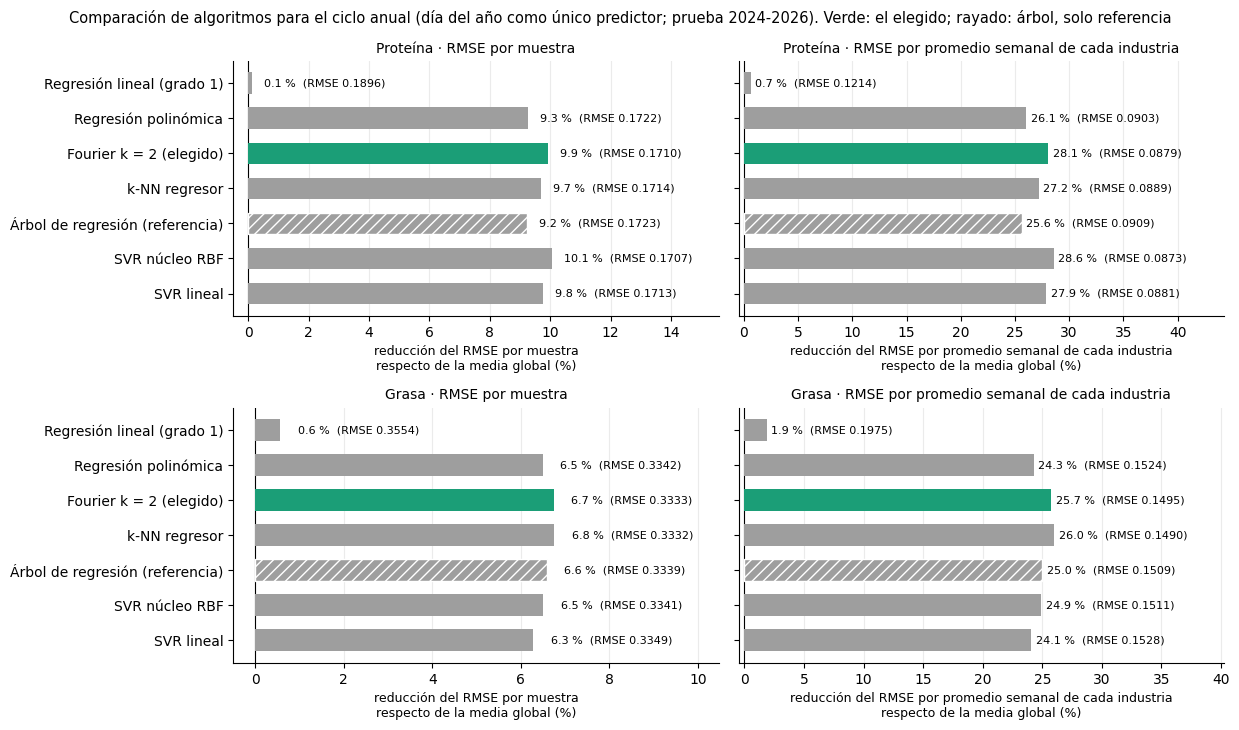

In [24]:
fig, ax = plt.subplots(2, 2, figsize=(12.5, 7.4))
claves = [k for k in NOM if k != "media"]
for i, v in enumerate(OBJ):
    s = cmpr[cmpr["objetivo"] == v].set_index("clave")
    for j, (col, tit, ref_col) in enumerate([("mejora RMSE vs media global (%)", "por muestra", "rmse"), ("mejora RMSE semanal vs media global (%)", "por promedio semanal de cada industria", "rmse_sem")]):
        a = ax[i, j]
        val = s.loc[claves, col].to_numpy()
        ypos = np.arange(len(claves))
        colores = ["#1b9e77" if k == "four" else "0.62" for k in claves]
        barras = a.barh(ypos, val, color=colores, height=0.62, zorder=3)
        for b_, k in zip(barras, claves):
            if k == "arbol":
                b_.set_hatch("///"); b_.set_edgecolor("white")
        for yy, vv, k in zip(ypos, val, claves):
            a.text(vv + 0.4, yy, f"{vv:.1f} %  (RMSE {s.loc[k, ref_col]:.4f})", va="center", fontsize=8)
        a.axvline(0, color="k", lw=0.8)
        a.set_xlim(min(0, val.min()) - 0.5, val.max() * 1.55)
        a.set_yticks(ypos); a.set_yticklabels([NOM[k] for k in claves] if j == 0 else [""] * len(ypos)); a.invert_yaxis()
        a.set_xlabel(f"reducción del RMSE {tit}\nrespecto de la media global (%)"); a.set_title(("Proteína" if v == "proteina" else "Grasa") + f" · RMSE {tit}")
        a.grid(axis="x", alpha=0.25); a.set_axisbelow(True)
fig.suptitle("Comparación de algoritmos para el ciclo anual (día del año como único predictor; prueba 2024-2026). Verde: el elegido; rayado: árbol, solo referencia", fontsize=10.5)
fig.tight_layout(); fig.savefig(SALIDA / "fig5_comparacion_algoritmos.png", dpi=DPI, bbox_inches="tight"); plt.show()

In [25]:
def f3(x, n=4):
    return f"{x:.{n}f}".replace(".", ",")

lineas = ["**Veredicto de la comparación (prueba 2024-2026, g/100 g).**", ""]
for v in OBJ:
    s = cmpr[cmpr["objetivo"] == v].set_index("clave").drop(index="media")
    mejor_m, mejor_s = s["rmse"].idxmin(), s["rmse_sem"].idxmin()
    fo = s.loc["four"]
    emp = [NOM[k] for k in s.index if k != "four" and abs(s.loc[k, "rmse_sem"] / fo["rmse_sem"] - 1) < 0.01]
    lineas.append(f"**{'Proteína' if v == 'proteina' else 'Grasa'}.** Menor RMSE por muestra: **{NOM[mejor_m]}** ({f3(s.loc[mejor_m, 'rmse'])}; Fourier k = 2: {f3(fo['rmse'])}). Menor RMSE semanal: **{NOM[mejor_s]}** ({f3(s.loc[mejor_s, 'rmse_sem'])}; Fourier k = 2: {f3(fo['rmse_sem'])}). "
                  f"A menos de 1 % del RMSE semanal de Fourier k = 2: {', '.join(emp) if emp else 'ninguno'}. La regresión lineal (grado 1) queda en {f3(s.loc['lin', 'rmse_sem'])} de RMSE semanal "
                  f"({f3(s.loc['lin', 'mejora RMSE semanal vs media global (%)'], 1)} % de mejora contra {f3(fo['mejora RMSE semanal vs media global (%)'], 1)} % de Fourier). Árbol (referencia): {f3(s.loc['arbol', 'rmse_sem'])}.")
lineas.append("")
display(Markdown("\n".join(lineas)))

**Veredicto de la comparación (prueba 2024-2026, g/100 g).**

**Proteína.** Menor RMSE por muestra: **SVR núcleo RBF** (0,1707; Fourier k = 2: 0,1710). Menor RMSE semanal: **SVR núcleo RBF** (0,0873; Fourier k = 2: 0,0879). A menos de 1 % del RMSE semanal de Fourier k = 2: SVR núcleo RBF, SVR lineal. La regresión lineal (grado 1) queda en 0,1214 de RMSE semanal (0,7 % de mejora contra 28,1 % de Fourier). Árbol (referencia): 0,0909.
**Grasa.** Menor RMSE por muestra: **k-NN regresor** (0,3332; Fourier k = 2: 0,3333). Menor RMSE semanal: **k-NN regresor** (0,1490; Fourier k = 2: 0,1495). A menos de 1 % del RMSE semanal de Fourier k = 2: k-NN regresor, Árbol de regresión (referencia). La regresión lineal (grado 1) queda en 0,1975 de RMSE semanal (1,9 % de mejora contra 25,7 % de Fourier). Árbol (referencia): 0,1509.


**Por qué esta familia, a la vista de los números de arriba.**
* **Hay un ciclo, y eso es lo que importa.** El salto grande es de la media global y la recta del tiempo (grado 1: 0,7 % de mejora del RMSE semanal en proteína y 1,9 % en grasa) a cualquier algoritmo que pueda curvarse: polinomio de grado 3, Fourier, k-NN, árbol y SVR mejoran el RMSE semanal entre 24 % y 29 %.
  La recta no sirve porque el ciclo anual sube y baja (el promedio de una recta a lo largo del año es casi la media global).
* **Entre los que aprendieron el ciclo las diferencias son chicas, y ninguno gana en todo.** En proteína el SVR con núcleo RBF tiene apenas menos error que Fourier k = 2 (RMSE semanal 0,0873 contra 0,0879, 0,7 % menos; por muestra 0,1707 contra 0,1710), y el SVR lineal y Fourier casi se igualan (0,0881);
  en grasa el k-NN lo supera por 0,3 % en el RMSE semanal (0,1490 contra 0,1495). Son diferencias de menos del 1 %, y entre todos esos algoritmos el orden cambia de un objetivo a otro: es un empate técnico, no una ventaja que justifique un modelo sin intervalos.
  El SVR, además, se ajusta con 10 000 filas al azar del entrenamiento y su error cambia con el sorteo (con otra semilla del sorteo quedaba peor que Fourier en grasa), así que no se lo toma como una ventaja estable.
  El error que queda es la variación entre tambos y un corrimiento de nivel común que ninguno predice con solo el día del año: con un único predictor y unas 800 muestras por día, un algoritmo más flexible no tiene estructura nueva que encontrar.
  (El `k` elegido del k-NN, 20 000, equivale a promediar una ventana de unos 25 días (±12) alrededor de la fecha: es un suavizador, no un modelo «local».)
* **Interpretabilidad.** La pregunta del trabajo (amplitud del ciclo, día del pico, cuánto vale 1 °C de anomalía) se responde con **coeficientes y sus intervalos por bootstrap de bloques** (sección 11); en Fourier, la amplitud y el día del pico salen de los coeficientes de seno y coseno.
  Con k-NN o con el SVR con núcleo habría que leer la curva predicha y no habría intervalos; el árbol da una curva en escalones (cortes por fecha) que no cierra suavemente entre diciembre y enero.
* **Cíclico por construcción.** Fourier cierra entre el 31-dic y el 1-ene; el polinomio no (sección 3). El k-NN lo logra porque se le dio el día codificado en círculo; el árbol, con el día crudo, trata el 1-ene y el 31-dic como extremos.
* **Costo.** Todos ajustan en una fracción de segundo salvo el SVR con núcleo, que se ajusta con 10 000 muestras porque su costo crece más que linealmente con las filas.
* **Lo que no cubre esta comparación.** Solo el ciclo (día del año); no se probó k-NN, árbol ni SVR con anomalía de temperatura e industria. Con ese predictor adicional, la regresión lineal permite además **separar** la estación de la temperatura y estimar un efecto por °C con intervalo (sección 11), cosa que los otros algoritmos no dan de forma directa.

## 14 · Datos usados en cada entrenamiento
Cuántas filas de la leche cruda entran en cada modelo de este cuaderno, cuáles se sacan y por qué, y cómo se reparten entre entrenamiento, validación y prueba. Proteína y grasa se ajustan **juntas** con las mismas filas
(una fila por objetivo, con los mismos números). La validación sale del propio pasado: cada año de 2021-2023 se valida con un modelo ajustado con los años anteriores (ventana que crece), y el modelo final se reajusta con todo hasta 2023;
por eso «entrenamiento» cuenta las filas anteriores a 2021 y «validación» las de 2021-2023 (las dos juntas son las que ajustan el modelo final). La prueba es 2024-2026 y no decide nada. Las submuestras de los algoritmos de la sección 13 figuran en la nota.

In [26]:
import datos_entrenamiento as DE
from IPython.display import display

N_ARCHIVO = int(tabla_limpieza["quedan"].iloc[0])
excl = [f"{r['paso']}: {miles(r['saca'])}" for _, r in tabla_limpieza.iloc[1:].iterrows() if r["saca"] > 0]
if len(D0) - len(D):
    excl.append(f"industria con menos de {RL.MIN_MUESTRAS_INDUSTRIA} muestras ({', '.join(chicas)}, se saca de todos los modelos): {miles(len(D0) - len(D))}")
MOTIVO = "; ".join(excl)
n_pre = int((D["fecha"] < "2021-01-01").sum()); n_val = int(val_m.sum()); n_pru = int(pru_m.sum()); n_h23 = int(ent_m.sum())
assert n_pre + n_val + n_pru == len(D)
PART = "temporal: hasta 2023 / prueba 2024-26; validación móvil 2021-23 (ventana que crece por año)"
NOTA_FINAL = f"el modelo final se reajusta con todo hasta 2023 ({miles(n_h23)} filas); proteína y grasa se ajustan juntas con las mismas filas"
ROT = {"proteina": "proteína", "grasa": "grasa"}
filas = []
DAT = "muestras de leche cruda con fecha, grasa, proteína y temperatura"

def reg(v, modelo, nota="", **kw):
    filas.append(DE.fila("III", f"{modelo}, {ROT[v]}", DAT, N_ARCHIVO, len(D), MOTIVO, entrenamiento=n_pre, validacion=n_val, prueba=n_pru, particion=PART, nota=nota or NOTA_FINAL, **kw))

for v in OBJ:
    reg(v, f"ciclo elegido ({ciclo_nombre})")
for v in OBJ:
    reg(v, f"ciclo + temperatura, modelo elegido ({elegido_nombre})")
for v in OBJ:
    filas.append(DE.fila("III", f"interpretación ({ciclo_nombre} + industria + anomalía de {NSTAR} d, grado 2), {ROT[v]}", DAT, N_ARCHIVO, len(D), MOTIVO, particion="sin partición: todos los datos 2019-2026, intervalos por bootstrap de bloques de 28 días",
                         nota=f"ciclo + industria + anomalía de {NSTAR} días con término cuadrático; {B} remuestreos; proteína y grasa con las mismas filas"))
for v in OBJ:
    filas.append(DE.fila("III", f"polinomio de grado 1 a 10 con pocas muestras, {ROT[v]}", DAT, N_ARCHIVO, N_POCAS + n_pru,
                         MOTIVO + f"; de las {miles(n_h23)} filas hasta 2023 solo entran {N_POCAS} al azar por sorteo", entrenamiento=N_POCAS, prueba=n_pru,
                         particion="temporal: {0} muestras al azar hasta 2023 / prueba 2024-26".format(N_POCAS), nota=f"{SORTEOS} sorteos; se promedia el error de prueba (figura 2, abajo)"))
for esq, g_, pasado in (("(a) todos los años", lo_a, False), ("(b) hasta 2023 → 2024-26", lo_b, True)):
    for v in OBJ:
        gg = g_[(g_["modelo"] == "ciclo") & (g_["objetivo"] == v)]
        inds = list(gg["industria"])
        n_te = int(round(gg["n"].mean()))
        if pasado:
            n_tr = int(round((ent_m.sum() - D[ent_m & D["cliente"].isin(inds).to_numpy()].groupby("cliente").size().reindex(inds).mean())))
        else:
            n_tr = int(round(len(D) - gg["n"].mean()))
        filas.append(DE.fila("III", f"industria afuera {esq}: ciclo, {ROT[v]}", DAT, N_ARCHIVO, len(D), MOTIVO, entrenamiento=n_tr, prueba=n_te,
                             particion=f"una industria afuera por vez ({len(inds)} industrias evaluadas)" + (", ajuste hasta 2023 y prueba 2024-26" if pasado else ""),
                             nota="entrenamiento y prueba son el promedio por industria dejada afuera; sin término de industria; proteína y grasa con las mismas filas"))
NOTA_ALG = {
    "lin": "polinomio de grado 1; sin submuestra", "poly": f"{poly_nombre}; sin submuestra",
    "knn": f"sin submuestra; k = {min(VALID_HP['knn'], key=lambda r: r[1])[0]} elegido por validación; se evalúa por día del año distinto",
    "arbol": f"sin submuestra; hojas de al menos 500 filas; profundidad {min(VALID_HP['arbol'], key=lambda r: r[1])[0]} elegida por validación",
    "svr_rbf": f"SUBMUESTRA: {miles(N_SVR)} filas al azar de las {miles(n_h23)} hasta 2023 (también en cada año de la validación); C = {min(VALID_HP['svr_rbf'], key=lambda r: r[1])[0]:g}",
    "svr_lin": f"SUBMUESTRA: {miles(N_SVR)} filas al azar de las {miles(n_h23)} hasta 2023 (también en cada año de la validación); C = {min(VALID_HP['svr_lin'], key=lambda r: r[1])[0]:g}",
}
for clave in ("lin", "poly", "knn", "arbol", "svr_rbf", "svr_lin"):
    filas.append(DE.fila("III", f"sección 13: {NOM[clave]}, proteína y grasa", "muestras de leche cruda (solo el día del año como predictor)", N_ARCHIVO, len(D), MOTIVO,
                         entrenamiento=n_pre, validacion=n_val, prueba=n_pru, particion=PART, nota=NOTA_ALG[clave] + "; el modelo final se reajusta con todo hasta 2023"))
display(DE.guardar(filas, "regresion_ciclo_leche_cruda"))

,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,III,"ciclo elegido (Fourier k=2), proteína","muestras de leche cruda con fecha, grasa, prot...",628035,150523,"sin fecha, sin grasa o sin proteína: 143.868; ...",477512,87701,213021,176790,temporal: hasta 2023 / prueba 2024-26; validac...,el modelo final se reajusta con todo hasta 202...
1,III,"ciclo elegido (Fourier k=2), grasa","muestras de leche cruda con fecha, grasa, prot...",628035,150523,"sin fecha, sin grasa o sin proteína: 143.868; ...",477512,87701,213021,176790,temporal: hasta 2023 / prueba 2024-26; validac...,el modelo final se reajusta con todo hasta 202...
2,III,"ciclo + temperatura, modelo elegido (ciclo + a...","muestras de leche cruda con fecha, grasa, prot...",628035,150523,"sin fecha, sin grasa o sin proteína: 143.868; ...",477512,87701,213021,176790,temporal: hasta 2023 / prueba 2024-26; validac...,el modelo final se reajusta con todo hasta 202...
3,III,"ciclo + temperatura, modelo elegido (ciclo + a...","muestras de leche cruda con fecha, grasa, prot...",628035,150523,"sin fecha, sin grasa o sin proteína: 143.868; ...",477512,87701,213021,176790,temporal: hasta 2023 / prueba 2024-26; validac...,el modelo final se reajusta con todo hasta 202...
4,III,interpretación (Fourier k=2 + industria + anom...,"muestras de leche cruda con fecha, grasa, prot...",628035,150523,"sin fecha, sin grasa o sin proteína: 143.868; ...",477512,477512,<NA>,<NA>,"sin partición: todos los datos 2019-2026, inte...",ciclo + industria + anomalía de 7 días con tér...
5,III,interpretación (Fourier k=2 + industria + anom...,"muestras de leche cruda con fecha, grasa, prot...",628035,150523,"sin fecha, sin grasa o sin proteína: 143.868; ...",477512,477512,<NA>,<NA>,"sin partición: todos los datos 2019-2026, inte...",ciclo + industria + anomalía de 7 días con tér...
6,III,"polinomio de grado 1 a 10 con pocas muestras, ...","muestras de leche cruda con fecha, grasa, prot...",628035,451165,"sin fecha, sin grasa o sin proteína: 143.868; ...",176870,80,<NA>,176790,temporal: 80 muestras al azar hasta 2023 / pru...,60 sorteos; se promedia el error de prueba (fi...
7,III,"polinomio de grado 1 a 10 con pocas muestras, ...","muestras de leche cruda con fecha, grasa, prot...",628035,451165,"sin fecha, sin grasa o sin proteína: 143.868; ...",176870,80,<NA>,176790,temporal: 80 muestras al azar hasta 2023 / pru...,60 sorteos; se promedia el error de prueba (fi...
8,III,"industria afuera (a) todos los años: ciclo, pr...","muestras de leche cruda con fecha, grasa, prot...",628035,150523,"sin fecha, sin grasa o sin proteína: 143.868; ...",477512,424455,<NA>,53057,una industria afuera por vez (9 industrias eva...,entrenamiento y prueba son el promedio por ind...
9,III,"industria afuera (a) todos los años: ciclo, grasa","muestras de leche cruda con fecha, grasa, prot...",628035,150523,"sin fecha, sin grasa o sin proteína: 143.868; ...",477512,424455,<NA>,53057,una industria afuera por vez (9 industrias eva...,entrenamiento y prueba son el promedio por ind...
